# Auckland Property Price Prediction -- Exploratory Data Analysis

Dataset: `cache/dvrs_with_team_external.parquet`, the consolidated table that
merges the native Auckland Council DVR sales/valuation data with every
externally sourced feature the team has produced: geocoding, flood hazard,
Unitary Plan zoning, aircraft-noise overlays, SA2 building-consent activity,
and walking/driving distance to the nearest supermarket and bus stop.

This notebook is exploration only -- no filtering, modeling or feature
pruning. It looks at distributions, missingness, relationships with the
target (`sale_price_gross`), and the new externally sourced columns
specifically.

## 1. Import data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 70)

df = pd.read_parquet("./cache/dvrs_with_team_external.parquet")
print(f"Loaded {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Loaded 92,010 rows, 56 columns


,valuation_roll_number,valuation_number_assessment,valuation_number_suffix,sale_date,district_code,sale_type,sales_group,sale_tenure,price_value_relationship,sale_price_gross,sale_price_net,sale_price_chattels,sale_price_other,capital_value,land_value,current_effective_valuation_date,situation_number,additional_situation_number,situation_name,certificate_of_title,land_area,zoning,actual_property_use,units_of_use,off_street_parking,building_age_indicator,building_condition_indicator,building_construction_indicator,building_site_coverage,building_total_floor_area,property_category,legal_description,mass_contour,mass_view,mass_scope_of_view,mass_total_floor_area,mass_deck,mass_workshop_laundry,mass_other_improvements,mass_garage_under_main_roof,mass_garage_freestanding,valuation_id_concat,longitude,latitude,in_flood_plain,in_flood_sensitive_area,dist_to_flood_plain_m,dist_to_flood_sensitive_area_m,unitary_plan_zone,linz_matched,walk_supermarket_network_m,walk_bus_stop_network_m,drive_supermarket_network_m,drive_bus_stop_network_m,noise_category_combination,sa2_new_dwellings_consented_12m
0,1,2501710000,NaN,25022026,14,S,701,1,1,1514000,1499000,15000,0,1400000,1025000,45413,166,NaN,Point Chevalier RD,335510,0,9C,91,1,1,192,GG,WI,80,87,RD192A,"Carport 1 DP 384040, Flat 1 DP 384040,",LV,N,N,87,Y,N,N,0,1,1_2501710000,174.706389,-36.865688,False,False,241.910185,4866.407069,60.0,True,1578.192284,54.442135,535.386978,0.000000,outside_current_overlay,20
1,1,2600010100,NaN,1042025,14,S,701,1,1,1515112,1507112,8000,0,1675000,1500000,44348,7,NaN,Montrose ST,NA118D/908,0.0403,9D,91,1,0,193,AA,WT,120,117,RD193B,Lot 2 DP 189123 403m2,LV,N,N,117,Y,N,N,0,0,1_2600010100,174.708779,-36.869417,False,False,194.452135,4614.989420,8.0,True,309.197383,173.432349,134.495189,155.505174,outside_current_overlay,7
2,1,4300000201,NaN,14022025,14,S,701,1,1,1622800,1609800,13000,0,1650000,1360000,44348,5,NaN,St Michaels AV,NA57C/301,0,9C,91,1,1,198,AA,WT,60,124,RD198B,"Flat 3 DP 103999, Lot 4 DP 7475 652m2",LV,N,N,124,Y,N,N,1,0,1_4300000201,174.702890,-36.861304,False,False,199.900952,4667.722058,60.0,True,1720.397633,68.370379,1122.801352,9.608944,outside_current_overlay,3
3,1,4300110000,NaN,17012025,14,S,701,1,1,2105000,2092000,13000,0,2600000,2325000,44348,35,NaN,St Michaels AV,NA405/218,0.0656,9B,91,1,1,193,AA,WT,120,123,RD193B,Lot 2 DP 15494 656m2,EF,N,N,123,Y,N,N,0,0,1_4300110000,174.700846,-36.862339,False,False,18.820703,4814.776819,18.0,True,1981.946279,329.919025,1502.064675,333.383823,outside_current_overlay,11
4,1,4300270001,NaN,11112025,14,S,701,1,2,1875000,1862000,13000,0,2300000,2025000,45413,66,NaN,St Michaels AV,115395,0.0396,9B,91,1,1,192,AA,WI,137,124,RD192B,Lot 1 DP 328302 396m2,EF,W,M,109,Y,N,N,1,0,1_4300270001,174.698847,-36.863616,False,False,6.764028,4804.594688,18.0,True,2224.730646,465.392323,1606.980701,493.788293,outside_current_overlay,9


### 1.1 Drop leakage / valuation columns

- `sale_price_net`, `sale_price_chattels`, `sale_price_other`: these sum
  to `sale_price_gross` (the target) by definition, so keeping them would
  be direct target leakage.
- `capital_value`, `land_value`: Auckland Council's own valuation of the
  property and land -- estimates of price, not physical property
  attributes. Keeping them lets a near-answer stand in for genuine
  predictive signal.

All five are dropped here, before any EDA or modeling touches them.


In [2]:
df = df.drop(columns=[
    "sale_price_net", "sale_price_chattels", "sale_price_other",
    "capital_value", "land_value",
])
print(f"Dropped sale_price_net/chattels/other, capital_value, land_value. {df.shape[1]} columns remain.")


Dropped sale_price_net/chattels/other, capital_value, land_value. 51 columns remain.


In [3]:
df.dtypes.to_frame("dtype")

,dtype
valuation_roll_number,str
valuation_number_assessment,str
valuation_number_suffix,str
sale_date,str
district_code,str
sale_type,str
sales_group,str
sale_tenure,str
price_value_relationship,str
sale_price_gross,str


## 2. Data overview

Most native columns come through as strings even where they're numeric
(a quirk of the source export), so dtypes alone don't show what's usable yet.
Missing-value share by column first, to see where the real gaps are.

In [4]:
missing = df.isna().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]
print(f"{len(missing)} / {df.shape[1]} columns have at least one missing value\n")
missing.round(2)

31 / 51 columns have at least one missing value



valuation_number_suffix             84.62
additional_situation_number         72.29
mass_other_improvements              7.85
mass_workshop_laundry                7.73
building_condition_indicator         7.61
building_construction_indicator      7.45
mass_deck                            7.33
building_age_indicator               7.23
walk_supermarket_network_m           7.00
mass_view                            6.11
mass_scope_of_view                   6.11
walk_bus_stop_network_m              6.04
mass_contour                         5.98
drive_supermarket_network_m          5.46
drive_bus_stop_network_m             5.46
unitary_plan_zone                    4.45
latitude                             4.45
in_flood_sensitive_area              4.45
in_flood_plain                       4.45
sa2_new_dwellings_consented_12m      4.45
noise_category_combination           4.45
dist_to_flood_sensitive_area_m       4.45
dist_to_flood_plain_m                4.45
longitude                         

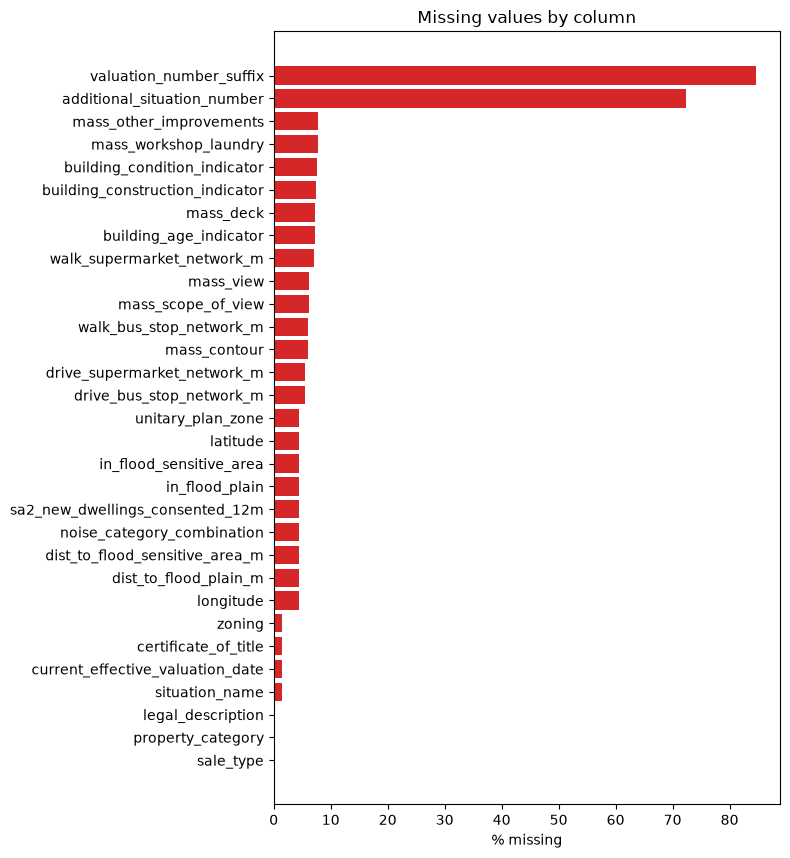

In [5]:
fig, ax = plt.subplots(figsize=(8, max(4, len(missing) * 0.28)))
ax.barh(missing.index[::-1], missing.values[::-1], color="tab:red")
ax.set_xlabel("% missing")
ax.set_title("Missing values by column")
plt.tight_layout()
plt.show()

## 3. Parse / type-fix for analysis

Numeric columns stored as strings are converted to numbers, and `sale_date`
(stored `DDMMYYYY` with no leading zeros, read right-to-left) is parsed into
a real date. This is the minimum needed to plot and correlate -- no row
filtering happens here.

In [6]:
def parse_sale_date(s):
    if pd.isna(s):
        return pd.NaT
    s = str(s)
    year = int(s[-4:])
    month = int(s[-6:-4])
    day = int(s[:-6])
    return pd.Timestamp(year=year, month=month, day=day)


df["sale_date_parsed"] = df["sale_date"].apply(parse_sale_date)
df["current_effective_valuation_date_parsed"] = pd.to_datetime(
    pd.to_numeric(df["current_effective_valuation_date"], errors="coerce"), unit="D", origin="1899-12-30"
)

numeric_cols = [
    "sale_price_gross",
    "land_area", "building_total_floor_area",
    "mass_total_floor_area", "building_site_coverage", "off_street_parking",
    "units_of_use", "mass_garage_under_main_roof", "mass_garage_freestanding",
    "longitude", "latitude",
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Team-external numeric columns are already float/Int64, just need a plain float dtype
external_numeric_cols = [
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
    "sa2_new_dwellings_consented_12m",
]
for col in external_numeric_cols:
    df[col] = df[col].astype(float)

# Nullable boolean dtype: rows with no LINZ coordinate match (linz_matched=False)
# have None here, not True/False. Casting to "boolean" (not plain bool/object)
# makes `|` propagate that as NA instead of silently treating it as False.
for col in ["in_flood_plain", "in_flood_sensitive_area"]:
    df[col] = df[col].astype("boolean")

print("sale_date_parsed range:", df["sale_date_parsed"].min().date(), "to", df["sale_date_parsed"].max().date())
df[numeric_cols + external_numeric_cols].describe().T

sale_date_parsed range: 2024-01-01 to 2026-08-21


,count,mean,std,min,25%,50%,75%,max
sale_price_gross,92010.0,2.616173e+06,3.899396e+07,1.000000,755000.000000,1000000.000000,1.450000e+06,1.792507e+09
land_area,92010.0,2.580082e-01,4.050016e+00,0.000000,0.000000,0.028650,6.650000e-02,4.820000e+02
building_total_floor_area,92010.0,2.254900e+02,4.633720e+03,0.000000,86.000000,127.000000,1.850000e+02,3.900000e+05
mass_total_floor_area,92010.0,1.157855e+02,7.865629e+01,0.000000,77.000000,108.000000,1.520000e+02,4.888000e+03
building_site_coverage,92010.0,1.322485e+02,2.103515e+03,0.000000,59.000000,94.000000,1.370000e+02,6.000600e+05
off_street_parking,92010.0,1.570775e+00,7.167405e+00,0.000000,0.000000,1.000000,2.000000e+00,9.800000e+02
units_of_use,92010.0,1.049125e+00,7.697022e-01,0.000000,1.000000,1.000000,1.000000e+00,1.550000e+02
mass_garage_under_main_roof,92010.0,7.599826e-01,9.464774e-01,0.000000,0.000000,0.000000,2.000000e+00,5.600000e+01
mass_garage_freestanding,92010.0,3.416368e-01,6.970015e-01,0.000000,0.000000,0.000000,0.000000e+00,2.000000e+01
longitude,87916.0,1.747796e+02,1.158947e-01,174.234241,174.700457,174.765891,1.748747e+02,1.755077e+02


## 4. Target variable: `sale_price_gross`

Right-skewed, as expected for prices across a wide market -- a few very high
sales stretch the distribution. `log1p` is the usual fix and is used
throughout the rest of this notebook for anything price-related.

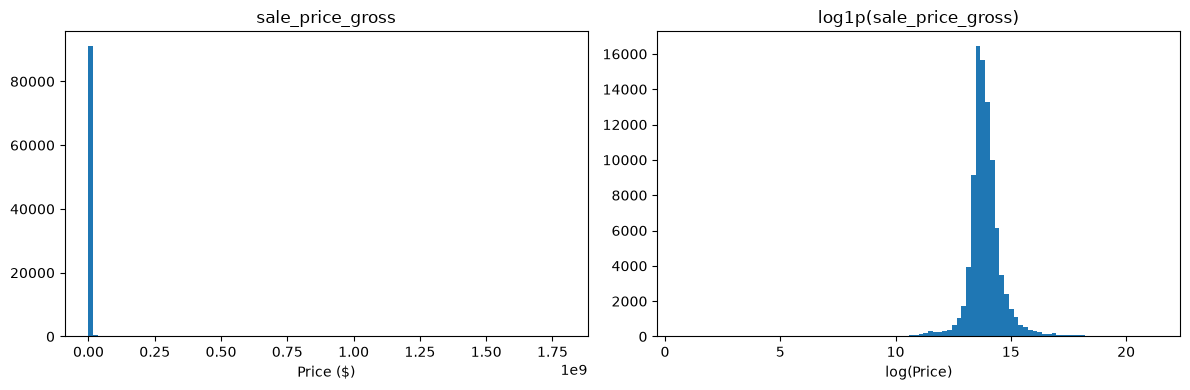

count    9.201000e+04
mean     2.616173e+06
std      3.899396e+07
min      1.000000e+00
25%      7.550000e+05
50%      1.000000e+06
75%      1.450000e+06
max      1.792507e+09
Name: sale_price_gross, dtype: float64

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["sale_price_gross"].dropna(), bins=100)
axes[0].set_title("sale_price_gross")
axes[0].set_xlabel("Price ($)")

axes[1].hist(np.log1p(df["sale_price_gross"].dropna()), bins=100)
axes[1].set_title("log1p(sale_price_gross)")
axes[1].set_xlabel("log(Price)")

plt.tight_layout()
plt.show()

df["sale_price_gross"].describe()

## 5. Data composition: the fields prior filtering decisions were based on

These five fields drove the row filters used in the modeling notebooks
(`train.ipynb` / `tmp.ipynb`). Shown here unfiltered, as context for how much
of the dataset each condition would keep -- not applied in this notebook.

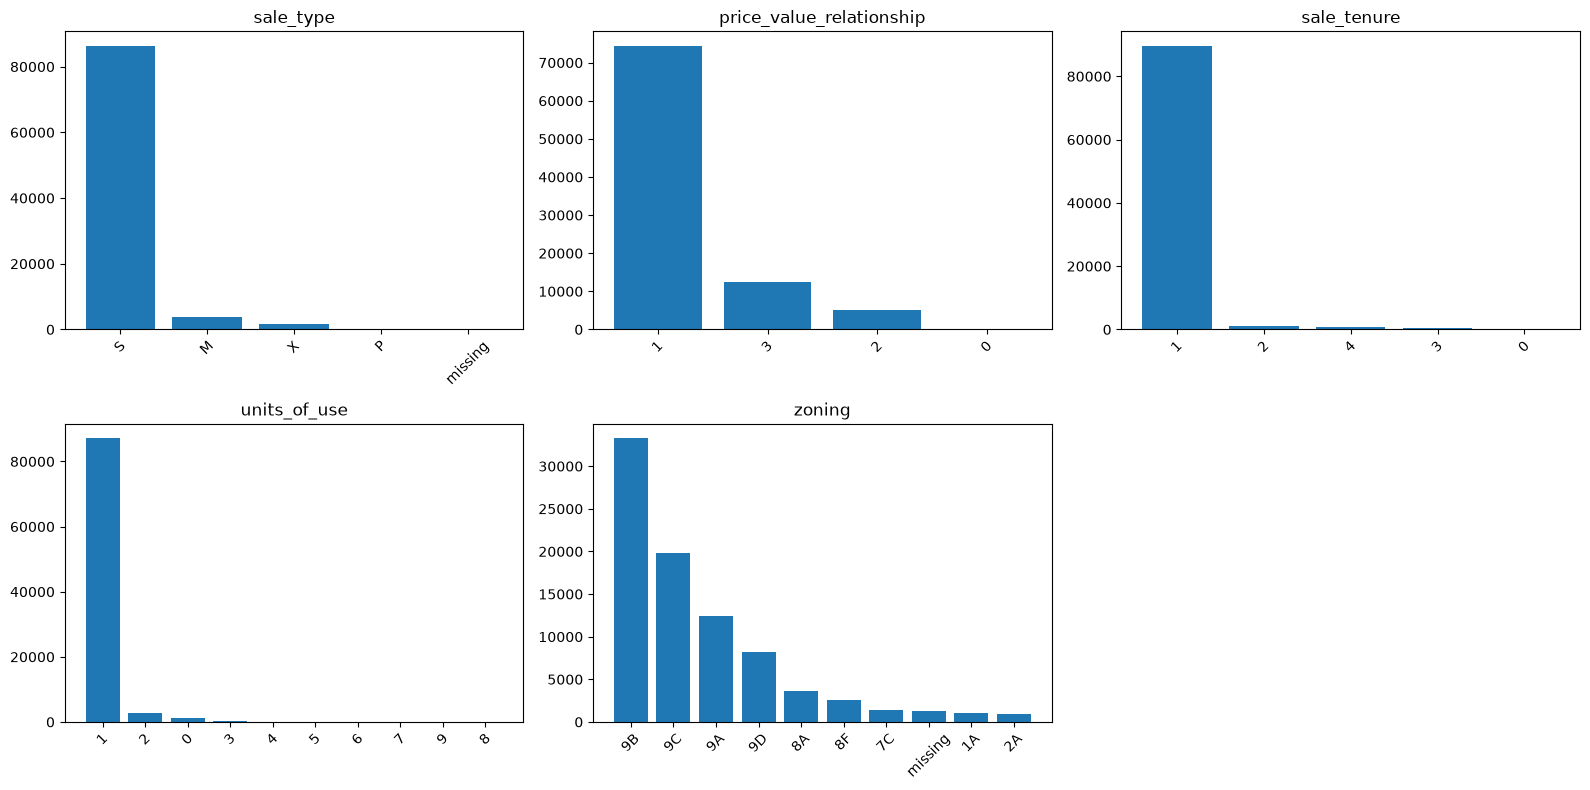


sale_type:
sale_type
S          86433
M           3900
X           1658
P             18
missing        1
Name: count, dtype: int64

price_value_relationship:
price_value_relationship
1    74490
3    12397
2     5077
0       46
Name: count, dtype: int64

sale_tenure:
sale_tenure
1    89730
2     1074
4      633
3      571
0        2
Name: count, dtype: int64

units_of_use:
units_of_use
1    87207
2     2903
0     1275
3      279
4      111
5       56
6       48
7       31
Name: count, dtype: int64


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, col, note in zip(axes.ravel(), [
    "sale_type", "price_value_relationship", "sale_tenure",
    "units_of_use", "zoning",
], ["", "", "", "", ""]):
    vc = df[col].fillna("missing").astype(str).value_counts(dropna=False).head(10)
    ax.bar(vc.index.astype(str), vc.values)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

for col in ["sale_type", "price_value_relationship", "sale_tenure", "units_of_use"]:
    print(f"\n{col}:")
    print(df[col].fillna("missing").astype(str).value_counts(dropna=False).head(8))

In [9]:
print("zoning, first character grouped (9=residential, 1=rural, 2=lifestyle per Council coding):")
print(df["zoning"].astype(str).str[0].value_counts(dropna=False).sort_index())
print()
print("linz_matched (new LINZ linkage found a coordinate):", df["linz_matched"].value_counts(dropna=False).to_dict())

zoning, first character grouped (9=residential, 1=rural, 2=lifestyle per Council coding):
zoning
0        473
1       1857
2       1249
3        181
4        190
5         84
6          1
7       1880
8       7854
9      76964
NaN     1277
Name: count, dtype: int64

linz_matched (new LINZ linkage found a coordinate): {True: 87916, False: 4094}


## 6. Numeric feature distributions

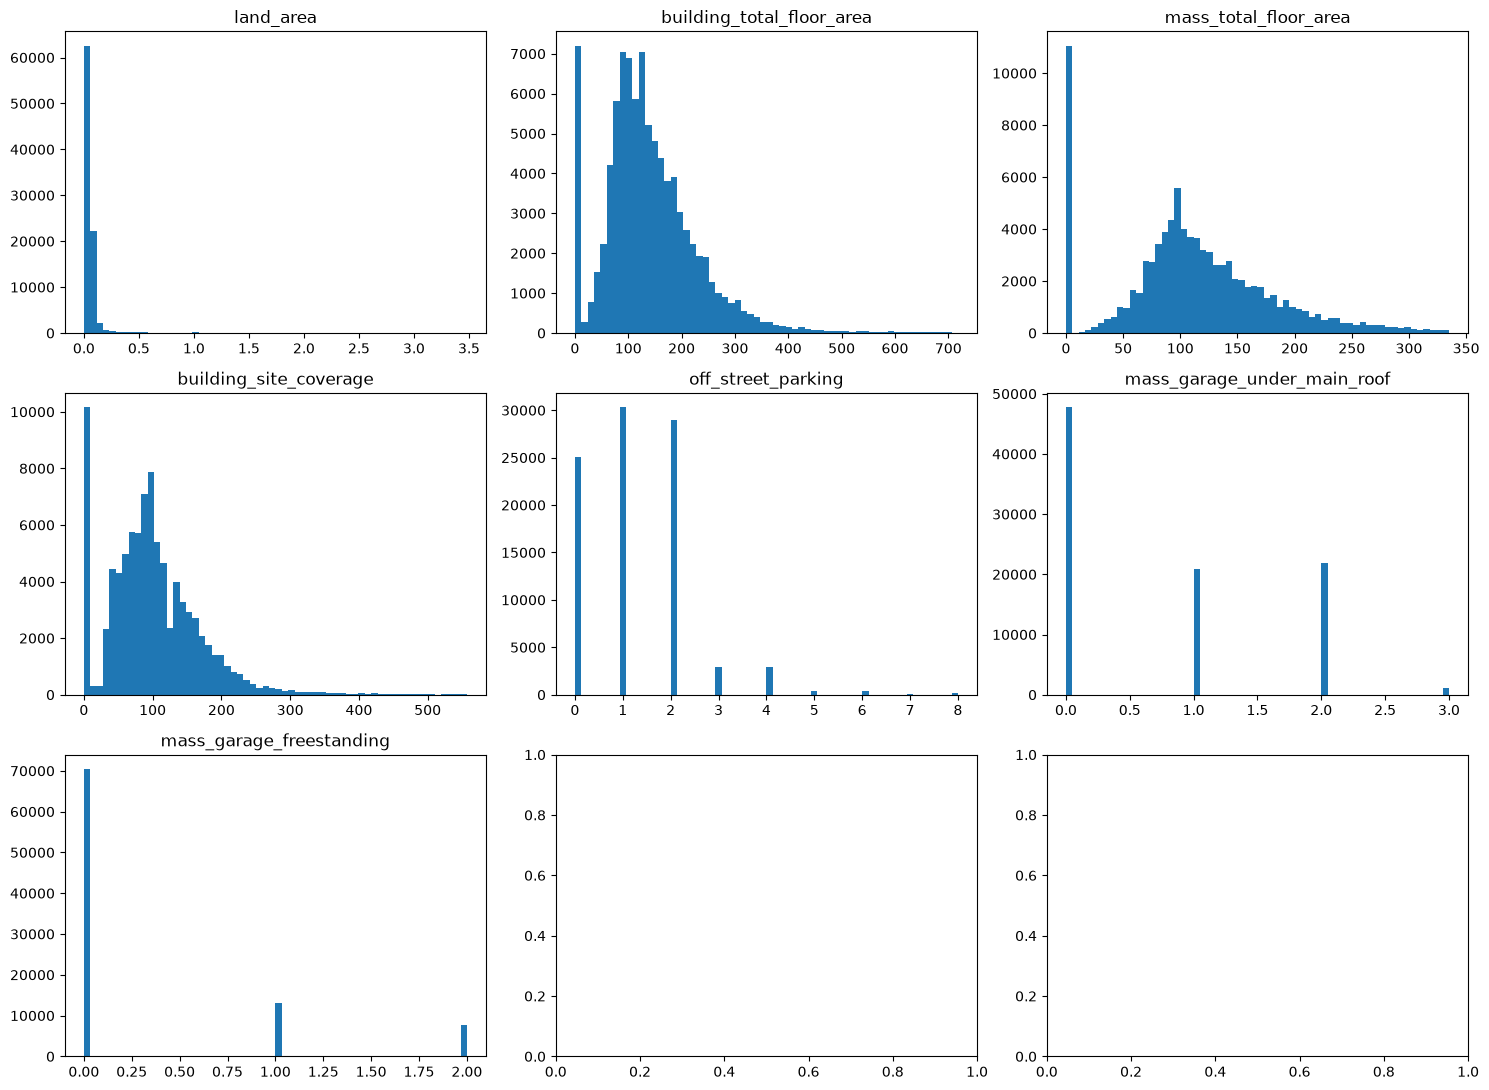

In [10]:
hist_cols = [
    "land_area", "building_total_floor_area",
    "mass_total_floor_area", "building_site_coverage", "off_street_parking",
    "mass_garage_under_main_roof", "mass_garage_freestanding",
]
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, col in zip(axes.ravel(), hist_cols):
    vals = df[col].dropna()
    vals = vals[vals <= vals.quantile(0.99)]  # trim extreme tail just for readability
    ax.hist(vals, bins=60)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 7. Numeric feature correlations with price

sale_price_gross                   1.000
off_street_parking                 0.331
building_site_coverage             0.099
building_total_floor_area          0.050
longitude                          0.021
land_area                          0.014
drive_supermarket_network_m        0.013
walk_supermarket_network_m         0.011
dist_to_flood_plain_m              0.006
drive_bus_stop_network_m          -0.003
walk_bus_stop_network_m           -0.003
dist_to_flood_sensitive_area_m    -0.006
latitude                          -0.009
sa2_new_dwellings_consented_12m   -0.014
mass_garage_freestanding          -0.016
mass_garage_under_main_roof       -0.023
mass_total_floor_area             -0.037
Name: sale_price_gross, dtype: float64


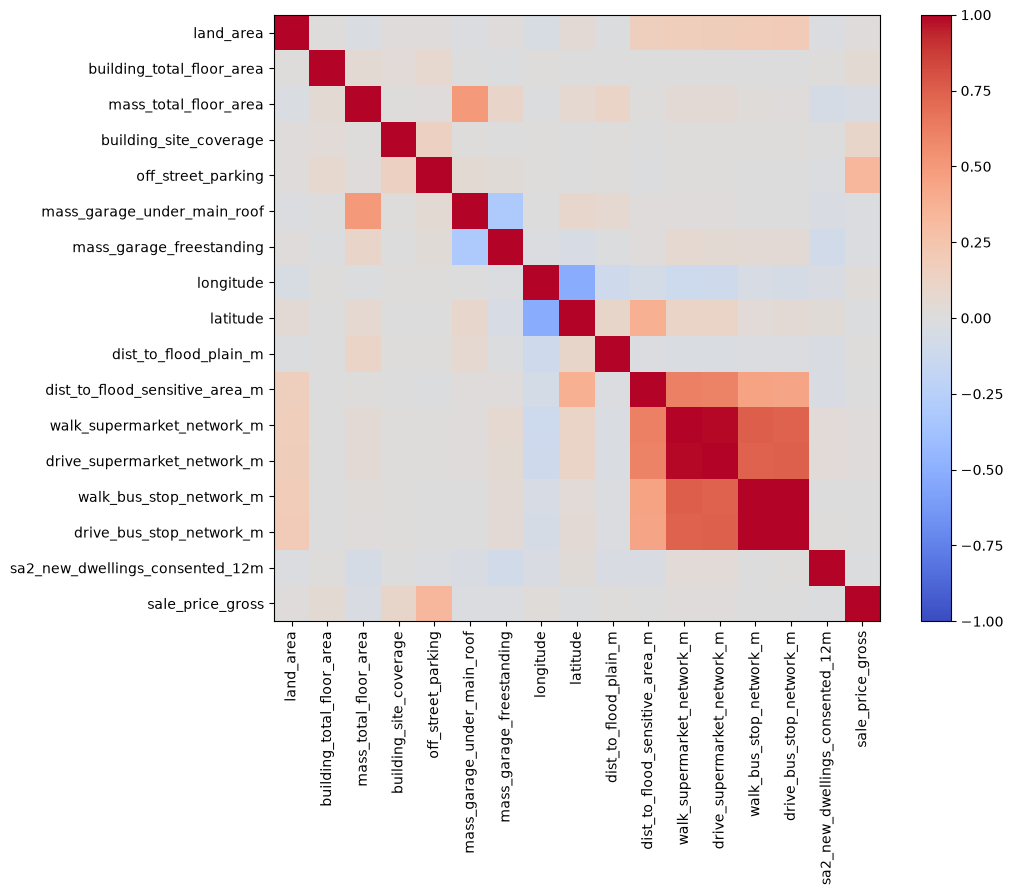

In [11]:
corr_cols = [
    "land_area", "building_total_floor_area",
    "mass_total_floor_area", "building_site_coverage", "off_street_parking",
    "mass_garage_under_main_roof", "mass_garage_freestanding",
    "longitude", "latitude", "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m",
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
    "sa2_new_dwellings_consented_12m",
]
corr_matrix = df[corr_cols + ["sale_price_gross"]].corr()
print(corr_matrix["sale_price_gross"].sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
labels = list(corr_matrix.columns)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
plt.colorbar(im)
plt.tight_layout()
plt.show()

## 8. Categorical features vs price

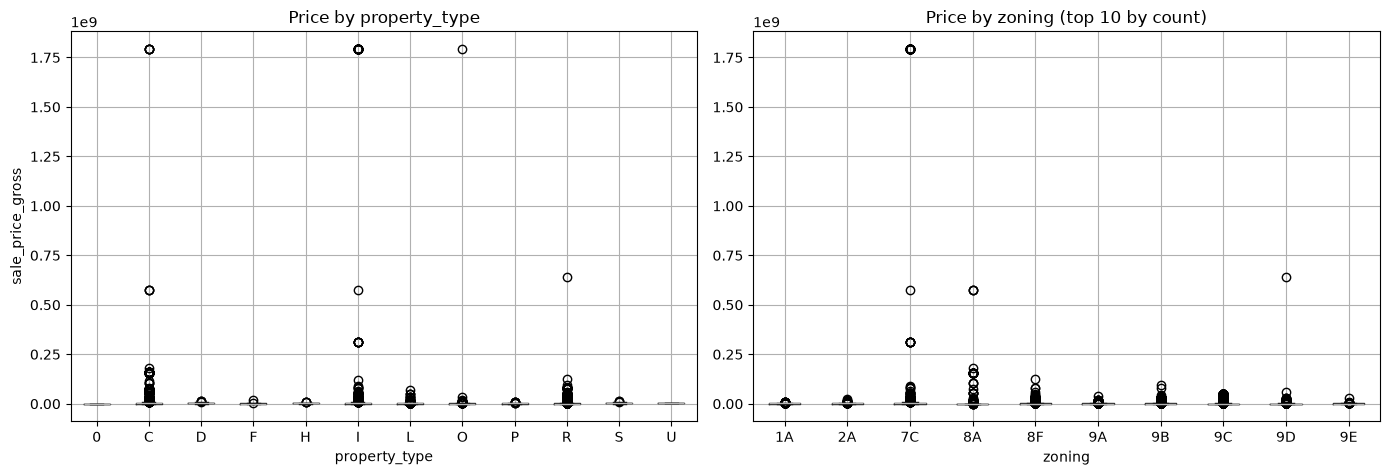

In [12]:
df["property_type"] = df["property_category"].str[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df.boxplot(column="sale_price_gross", by="property_type", ax=axes[0])
axes[0].set_title("Price by property_type")
axes[0].set_ylabel("sale_price_gross")

top_zones = df["zoning"].value_counts().head(10).index
df[df["zoning"].isin(top_zones)].boxplot(column="sale_price_gross", by="zoning", ax=axes[1])
axes[1].set_title("Price by zoning (top 10 by count)")

plt.suptitle("")
plt.tight_layout()
plt.show()

## 9. Geographic distribution

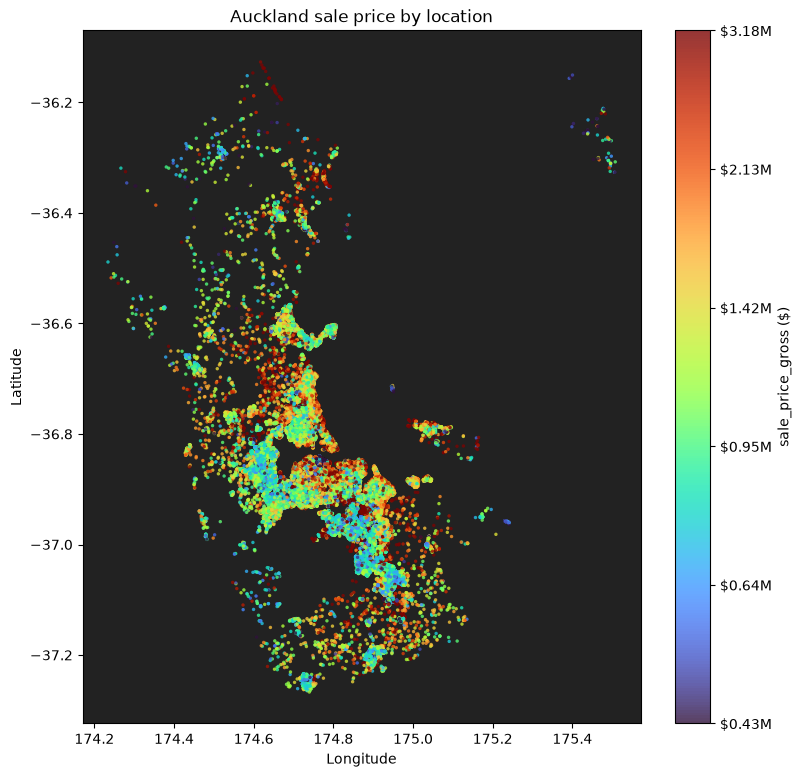

In [13]:
geo = df[["longitude", "latitude", "sale_price_gross"]].dropna().sample(frac=1, random_state=42)
geo_color = np.log1p(geo["sale_price_gross"])
vmin, vmax = geo_color.quantile([0.05, 0.95])

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(
    geo["longitude"], geo["latitude"],
    c=geo_color, cmap="turbo", vmin=vmin, vmax=vmax, s=6, alpha=0.8, linewidths=0,
)
cbar = plt.colorbar(sc, label="sale_price_gross ($)")
ticks = np.linspace(vmin, vmax, 6)
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"${np.expm1(t) / 1e6:.2f}M" for t in ticks])
ax.set_facecolor("#222222")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Auckland sale price by location")
plt.show()

## 10. Price trend over time

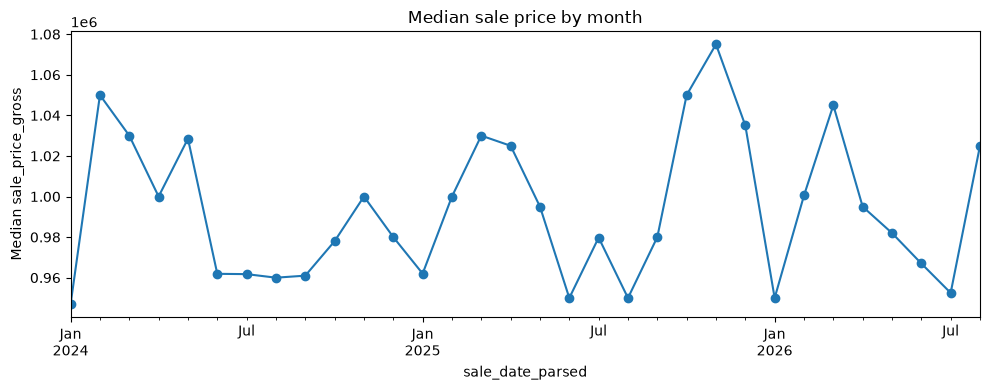

In [14]:
monthly = df.groupby(df["sale_date_parsed"].dt.to_period("M"))["sale_price_gross"].median()
fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(ax=ax, marker="o")
ax.set_ylabel("Median sale_price_gross")
ax.set_title("Median sale price by month")
plt.tight_layout()
plt.show()

## 11. Flood hazard

Existing external feature, included here for a complete EDA pass before the
new team-sourced features below.

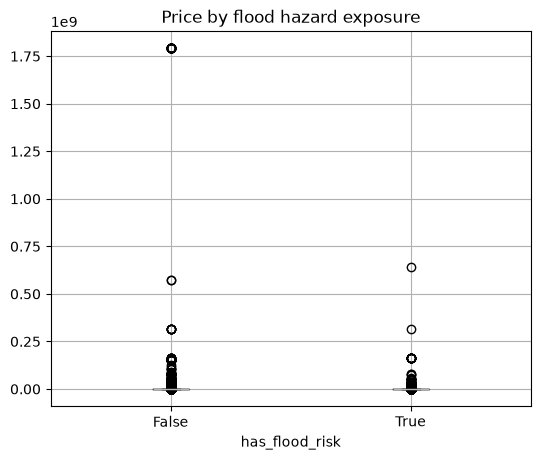

has_flood_risk
False    1000000.0
True      875000.0
Name: sale_price_gross, dtype: float64


In [15]:
df["has_flood_risk"] = df["in_flood_plain"] | df["in_flood_sensitive_area"]

fig, ax = plt.subplots(figsize=(6, 5))
df.boxplot(column="sale_price_gross", by="has_flood_risk", ax=ax)
ax.set_title("Price by flood hazard exposure")
plt.suptitle("")
plt.show()

print(df.groupby("has_flood_risk")["sale_price_gross"].median())

## 12. New team-sourced external features

Five columns new to this consolidated file:

- `noise_category_combination` -- which aircraft-noise overlay (if any) the
  property sits in (current planning snapshot).
- `sa2_new_dwellings_consented_12m` -- new dwellings consented in the
  property's SA2 in the 12 months before sale.
- `walk_supermarket_network_m` / `drive_supermarket_network_m` -- road-network
  walking / driving distance to the nearest supermarket.
- `walk_bus_stop_network_m` / `drive_bus_stop_network_m` -- same, for the
  nearest bus stop.

### 12.1 Missingness

All five have some gaps (1-3.4%), concentrated in rows the network-routing
step couldn't resolve (e.g. outside the routable extent, or no reachable
facility).

In [16]:
new_cols = [
    "noise_category_combination", "sa2_new_dwellings_consented_12m",
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
]
df[new_cols].isna().mean().mul(100).round(2).to_frame("% missing")

,% missing
noise_category_combination,4.45
sa2_new_dwellings_consented_12m,4.45
walk_supermarket_network_m,7.00
drive_supermarket_network_m,5.46
walk_bus_stop_network_m,6.04
drive_bus_stop_network_m,5.46


### 12.2 Distributions

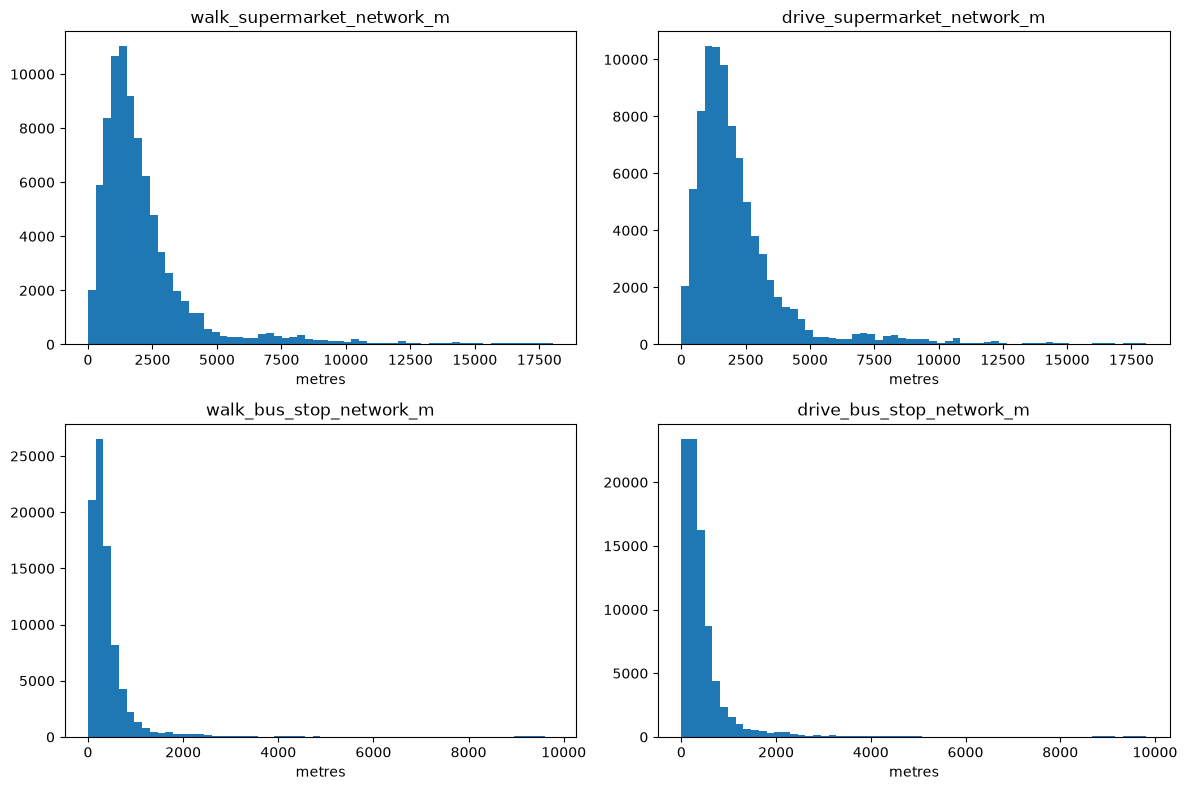

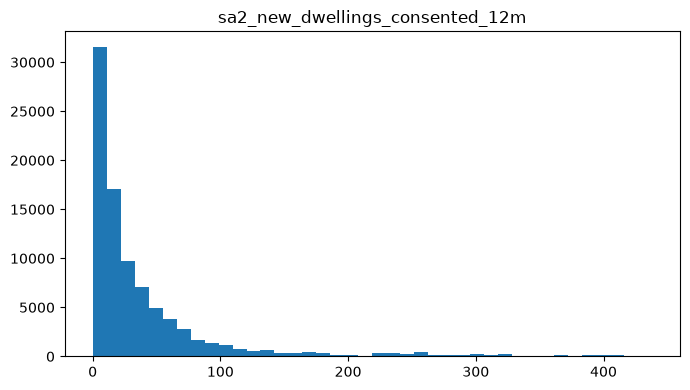

,count,mean,std,min,25%,50%,75%,max
walk_supermarket_network_m,85566.0,2463.961928,3205.408582,0.0,1046.462679,1648.921386,2583.423222,51387.099776
drive_supermarket_network_m,86985.0,2511.232474,3188.030923,0.0,1083.499580,1714.546273,2690.743817,51547.710075
walk_bus_stop_network_m,86457.0,645.038409,2038.506370,0.0,166.291128,294.889977,491.265835,39466.030017
drive_bus_stop_network_m,86985.0,665.735650,2052.864948,0.0,151.462774,303.010872,522.896387,39410.692881
sa2_new_dwellings_consented_12m,87916.0,38.958472,61.718372,0.0,6.000000,18.000000,44.000000,438.000000


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
dist_cols = [
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
]
for ax, col in zip(axes.ravel(), dist_cols):
    vals = df[col].dropna()
    vals = vals[vals <= vals.quantile(0.99)]
    ax.hist(vals, bins=60)
    ax.set_title(col)
    ax.set_xlabel("metres")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["sa2_new_dwellings_consented_12m"].dropna(), bins=40)
ax.set_title("sa2_new_dwellings_consented_12m")
plt.tight_layout()
plt.show()

df[dist_cols + ["sa2_new_dwellings_consented_12m"]].describe().T

### 12.3 Aircraft-noise overlay: counts and price

noise_category_combination
outside_current_overlay                                 83331
Auckland Airport - aircraft noise notification area      3383
Auckland Airport - moderate aircraft noise area           876
Auckland Airport - high aircraft noise area               135
Ardmore Airport - outer control boundary (55dBA)          116
Whenuapai Airbase - noise control area (55dBA)             48
North Shore Airport - Outer control boundary (55dBA)        8
Whenuapai Airbase- noise control area (65dBA)               6
Ardmore Airport - inner control boundary (60dBA)            6
North Shore Airport - air noise boundary (65dBA)            3
Kaipara Flats Airfield - Air noise boundary (55dBA)         2
Ardmore Airport -  noise boundary (65dBA)                   2
Name: count, dtype: int64[pyarrow]


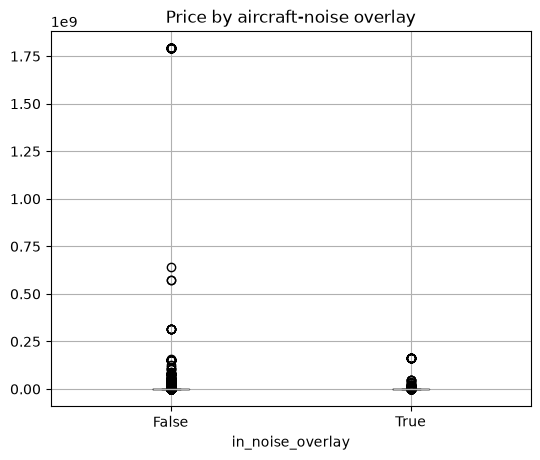

                  count     median
in_noise_overlay                  
False             83331  1000000.0
True               4585   855000.0


In [18]:
noise_counts = df["noise_category_combination"].value_counts()
print(noise_counts)

df["in_noise_overlay"] = df["noise_category_combination"] != "outside_current_overlay"

fig, ax = plt.subplots(figsize=(6, 5))
df.boxplot(column="sale_price_gross", by="in_noise_overlay", ax=ax)
ax.set_title("Price by aircraft-noise overlay")
plt.suptitle("")
plt.show()

print(df.groupby("in_noise_overlay")["sale_price_gross"].agg(["count", "median"]))

### 12.4 New numeric features vs price

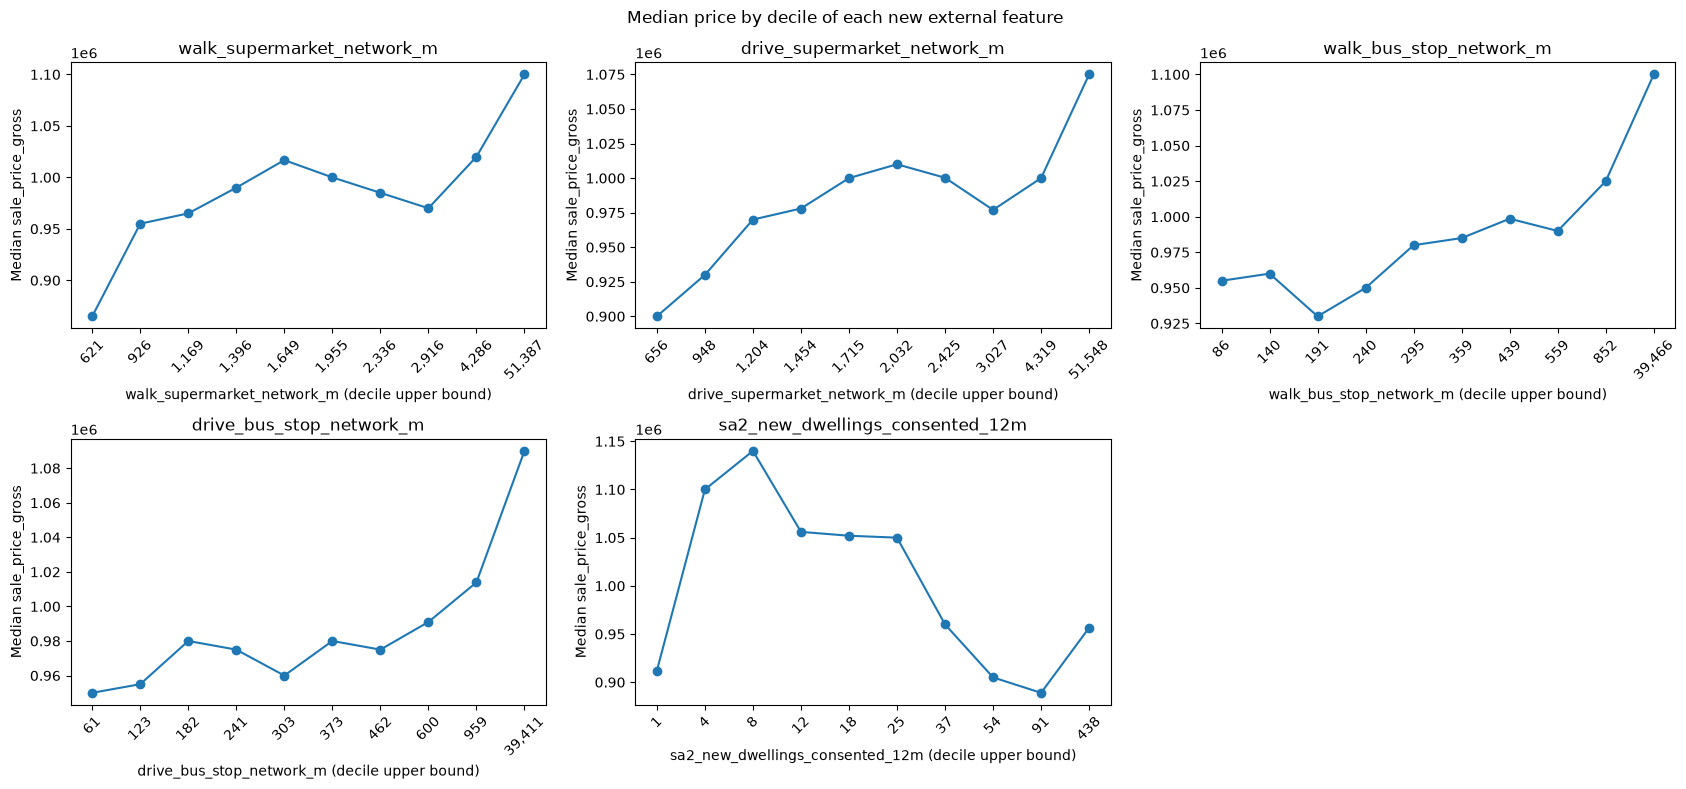

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
num_vs_price_cols = [
    "walk_supermarket_network_m", "drive_supermarket_network_m",
    "walk_bus_stop_network_m", "drive_bus_stop_network_m",
    "sa2_new_dwellings_consented_12m",
]
for ax, col in zip(axes.ravel()[:5], num_vs_price_cols):
    valid = df[[col, "sale_price_gross"]].dropna()
    bins = pd.qcut(valid[col], 10, duplicates="drop")
    med = valid.groupby(bins, observed=True)["sale_price_gross"].median()
    ax.plot(range(len(med)), med.values, marker="o")
    ax.set_xticks(range(len(med)))
    ax.set_xticklabels([f"{iv.right:,.0f}" for iv in med.index], rotation=45)
    ax.set_xlabel(f"{col} (decile upper bound)")
    ax.set_ylabel("Median sale_price_gross")
    ax.set_title(col)

axes[1, 2].axis("off")
plt.suptitle("Median price by decile of each new external feature")
plt.tight_layout()
plt.show()

### 12.5 Do the new walk/drive distances just duplicate each other?

They measure the same underlying thing (proximity to supermarket / bus stop)
two ways (walking vs driving network). High correlation here would matter
for a later multicollinearity-pruning step, same as the earlier
`tmp2.ipynb` pipeline found for the straight-line vs network distances.

                             walk_supermarket_network_m  \
walk_supermarket_network_m                        1.000   
drive_supermarket_network_m                       0.990   
walk_bus_stop_network_m                           0.751   
drive_bus_stop_network_m                          0.738   

                             drive_supermarket_network_m  \
walk_supermarket_network_m                         0.990   
drive_supermarket_network_m                        1.000   
walk_bus_stop_network_m                            0.739   
drive_bus_stop_network_m                           0.747   

                             walk_bus_stop_network_m  drive_bus_stop_network_m  
walk_supermarket_network_m                     0.751                     0.738  
drive_supermarket_network_m                    0.739                     0.747  
walk_bus_stop_network_m                        1.000                     0.992  
drive_bus_stop_network_m                       0.992                     1.000 

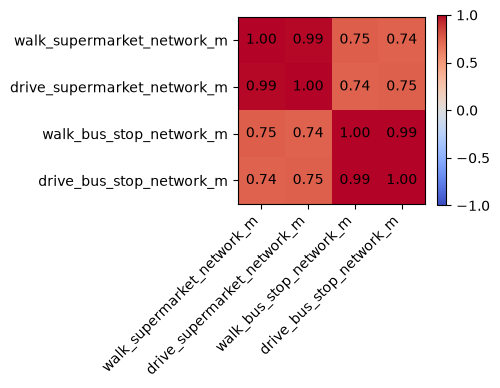

In [20]:
dist_corr = df[dist_cols].corr()
print(dist_corr.round(3))

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(dist_corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(dist_cols))); ax.set_xticklabels(dist_cols, rotation=45, ha="right")
ax.set_yticks(range(len(dist_cols))); ax.set_yticklabels(dist_cols)
for i in range(len(dist_cols)):
    for j in range(len(dist_cols)):
        ax.text(j, i, f"{dist_corr.iloc[i, j]:.2f}", ha="center", va="center")
plt.colorbar(im)
plt.tight_layout()
plt.show()

**Decision:** walking and driving distance to the same facility are
effectively the same signal (r=0.988 for supermarket, r=0.992 for bus
stop). Keep the walking distance for each facility -- the better proxy
for pedestrian-scale amenity access -- and drop the driving one.


In [21]:
df = df.drop(columns=["drive_supermarket_network_m", "drive_bus_stop_network_m"])
print(f"Dropped drive_supermarket_network_m, drive_bus_stop_network_m. {df.shape[1]} columns remain.")


Dropped drive_supermarket_network_m, drive_bus_stop_network_m. 54 columns remain.


## 13. EDA summary

- `sale_price_net`, `sale_price_chattels`, `sale_price_other`,
  `capital_value` and `land_value` were all dropped at the start
  (section 1.1): the first three are literal components of the target
  (target leakage), and the valuation columns are Auckland Council's
  own price estimates rather than physical property attributes.
- Target (`sale_price_gross`) is right-skewed; `log1p` is the natural
  transform, consistent with the modeling notebooks.
- With the valuation columns removed, `off_street_parking` and
  `building_site_coverage` are the strongest remaining numeric
  correlates of price, though all are far weaker than `capital_value`
  was -- expected, since location and size are now doing the work
  valuation used to.
- Most rows (`sale_type == "S"`, `price_value_relationship == "1"`,
  `sale_tenure == "1"`, `units_of_use == "1"`) are already the "clean"
  case; the filters used in modeling remove a real but modest share of
  the data.
- Flood hazard and aircraft-noise exposure cover a small minority of
  properties and show only a weak relationship with price on their
  own, at least without controlling for location.
- The four new walk/drive distance columns were highly correlated with
  each other (walking vs driving to the same facility type: r=0.988 for
  supermarket, r=0.992 for bus stop), so `drive_supermarket_network_m`
  and `drive_bus_stop_network_m` were dropped (section 12.5), keeping
  only the walking distance per facility.
- `sa2_new_dwellings_consented_12m` and the noise overlay add new,
  previously unexplored information, worth carrying into the next
  modeling pass on `final.ipynb`.


## 14. Ablation study: does the external data actually help?

The core evidence for whether the externally sourced features earn their
place. Two XGBoost models are trained on **identical, time-respecting
5-fold splits**: each fold trains only on sales *before* a cutoff date and
tests on the sales immediately *after* it (an expanding window), the same
"past predicts future" principle as a real deployment, rather than a random
shuffle.

- **Baseline** -- native Auckland Council property features only
  (`capital_value`/`land_value` and the price-component columns were already
  dropped in section 1.1 as leakage/valuation risks, so "property features"
  here means physical attributes: size, age, condition, construction, zoning
  code, etc.).
- **Augmented** -- baseline + every external feature this project has
  produced: geocoding, Unitary Plan zone, flood hazard, aircraft-noise
  overlay, SA2 consent activity, and walking distance to supermarket / bus
  stop.

For each fold both models see exactly the same train/test rows, so the
difference in error is attributable to the extra features, not to a
different split. A paired bootstrap on the out-of-fold predictions turns
that difference into a 95% confidence interval, which is what lets us say
whether the gain is real or could be noise.

### 14.1 Filter to reliable, genuine owner-occupier market sales

Same six filters used throughout the project's modeling notebooks
(`train.ipynb`, `tmp.ipynb`, `tmp2.ipynb`).

In [22]:
df_cv = df.copy()
assert "capital_value" not in df_cv.columns and "land_value" not in df_cv.columns, (
    "capital_value / land_value leaked back into df_cv -- they must stay dropped "
    "from the ablation feature set, same as the rest of this notebook"
)
print("Confirmed: capital_value / land_value are not present in df_cv")

before = len(df_cv)
df_cv = df_cv[df_cv["zoning"].astype(str).str[0].isin(["9", "1", "2"])]
print(f"Residential / rural / lifestyle zoning only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["units_of_use"] == 1]
print(f"Single unit of use only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["sale_tenure"].astype(str) == "1"]
print(f"Freehold sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["sale_type"] == "S"]
print(f"Single-property sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["price_value_relationship"] == "1"]
print(f"Arm's-length market sales only: {len(df_cv):,} / {before:,} rows kept")

before = len(df_cv)
df_cv = df_cv[df_cv["linz_matched"]]
print(f"LINZ-matched coordinate available: {len(df_cv):,} / {before:,} rows kept")

# Sort chronologically -- required for TimeSeriesSplit below, which assumes
# row order IS time order (it does not sort for you).
df_cv = df_cv.sort_values("sale_date_parsed").reset_index(drop=True)
print(f"\nFinal filtered shape: {df_cv.shape}")
print(f"Date range: {df_cv['sale_date_parsed'].min().date()} to {df_cv['sale_date_parsed'].max().date()}")

Confirmed: capital_value / land_value are not present in df_cv
Residential / rural / lifestyle zoning only: 80,070 / 92,010 rows kept
Single unit of use only: 77,370 / 80,070 rows kept
Freehold sales only: 76,395 / 77,370 rows kept


Single-property sales only: 74,112 / 76,395 rows kept
Arm's-length market sales only: 61,244 / 74,112 rows kept
LINZ-matched coordinate available: 59,798 / 61,244 rows kept

Final filtered shape: (59798, 54)
Date range: 2024-01-01 to 2026-08-18


### 14.2 Baseline vs augmented feature sets

`property_type`, `has_flood_risk` and `in_noise_overlay` were already
derived earlier in the notebook (sections 8, 11, 12.3); recomputed here too
so this section stands on its own.

In [23]:
df_cv["property_type"] = df_cv["property_category"].str[0]
df_cv["sale_year"] = df_cv["sale_date_parsed"].dt.year
df_cv["sale_month"] = df_cv["sale_date_parsed"].dt.month
df_cv["sale_quarter"] = df_cv["sale_date_parsed"].dt.quarter
df_cv["has_flood_risk"] = df_cv["in_flood_plain"] | df_cv["in_flood_sensitive_area"]
df_cv["in_noise_overlay"] = df_cv["noise_category_combination"] != "outside_current_overlay"
df_cv["unitary_plan_zone"] = df_cv["unitary_plan_zone"].fillna(-1).astype(int).astype(str)

BASELINE_CAT = [
    "zoning", "building_age_indicator", "building_condition_indicator",
    "building_construction_indicator", "mass_contour", "mass_view", "mass_scope_of_view",
    "mass_deck", "mass_workshop_laundry", "mass_other_improvements",
    "property_type", "actual_property_use",
]
BASELINE_NUM = [
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "building_site_coverage", "off_street_parking",
    "mass_garage_under_main_roof", "mass_garage_freestanding",
    "sale_year", "sale_month", "sale_quarter",
]
BASELINE_BOOL = []

EXTERNAL_CAT = ["unitary_plan_zone", "noise_category_combination"]
EXTERNAL_NUM = [
    "longitude", "latitude", "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m",
    "sa2_new_dwellings_consented_12m", "walk_supermarket_network_m", "walk_bus_stop_network_m",
]
EXTERNAL_BOOL = ["in_flood_plain", "in_flood_sensitive_area", "has_flood_risk", "in_noise_overlay"]

for col in BASELINE_CAT:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)
for col in EXTERNAL_CAT:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)

LOG_COLS = [
    "land_area", "building_total_floor_area", "mass_total_floor_area",
    "walk_supermarket_network_m", "walk_bus_stop_network_m",
]
for col in LOG_COLS:
    df_cv[col] = np.log1p(df_cv[col])

baseline_cols = BASELINE_CAT + BASELINE_NUM + BASELINE_BOOL
augmented_cols = baseline_cols + EXTERNAL_CAT + EXTERNAL_NUM + EXTERNAL_BOOL
all_cat = BASELINE_CAT + EXTERNAL_CAT
all_num = BASELINE_NUM + EXTERNAL_NUM
all_bool = BASELINE_BOOL + EXTERNAL_BOOL

print(f"Baseline:  {len(baseline_cols)} features")
print(f"Augmented: {len(augmented_cols)} features (+{len(augmented_cols) - len(baseline_cols)} external)")

Baseline:  22 features


Augmented: 35 features (+13 external)


### 14.3 5-fold time-series cross-validated ablation

Rows are sorted chronologically (section 14.1) and split with
`TimeSeriesSplit(n_splits=5)`: fold 1 trains on the earliest ~1/6 of sales
and tests on the next ~1/6; fold 2 trains on the first ~2/6 and tests on the
next ~1/6; and so on, each fold's training window expanding forward in
time. No model ever trains on a sale that happens after the sales it's
tested on. The very earliest ~1/6 of rows are training-only -- there's no
"past" before them to predict them from, so they never appear in a test
fold.

For each fold: fit the ordinal encoder and the outlier trim (1st-99th
percentile of price, same rule used throughout the project) on the training
rows only, then train a baseline and an augmented XGBoost model on the
*identical* train rows and evaluate both on the *identical* test rows. Out-
of-fold predictions are kept for the bootstrap and per-suburb analysis
below. Because each fold's training set is a different size (expanding
window), the per-fold results below partly reflect "does the model improve
as more training history accumulates" as well as fold-to-fold variance --
unlike a shuffled CV, where fold size is constant and differences are
closer to pure noise.

In [24]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBRegressor


def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))


def mae(y, yhat):
    return np.mean(np.abs(y - yhat))


def mape(y, yhat):
    return np.mean(np.abs((y - yhat) / y)) * 100


XGB_PARAMS = dict(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1,
)

y_all = df_cv["sale_price_gross"].values
kf = TimeSeriesSplit(n_splits=5)

fold_rows = []
oof_rows = []

for fold_i, (train_idx, test_idx) in enumerate(kf.split(df_cv), start=1):
    train_df = df_cv.iloc[train_idx]
    test_df = df_cv.iloc[test_idx]

    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    encoder.fit(train_df[all_cat])

    X_train = train_df[augmented_cols].copy()
    X_test = test_df[augmented_cols].copy()
    X_train[all_cat] = encoder.transform(train_df[all_cat])
    X_test[all_cat] = encoder.transform(test_df[all_cat])
    for col in all_bool:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    num_nan_cols = [c for c in all_num if X_train[c].isna().any() or X_test[c].isna().any()]
    train_medians = X_train[num_nan_cols].median()
    X_train[num_nan_cols] = X_train[num_nan_cols].fillna(train_medians)
    X_test[num_nan_cols] = X_test[num_nan_cols].fillna(train_medians)

    y_train = train_df["sale_price_gross"].values
    y_test = test_df["sale_price_gross"].values

    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
    X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]
    test_idx_f = test_idx[test_keep]

    base_model = XGBRegressor(**XGB_PARAMS)
    base_model.fit(X_train_f[baseline_cols], y_train_f)
    base_pred = base_model.predict(X_test_f[baseline_cols])

    aug_model = XGBRegressor(**XGB_PARAMS)
    aug_model.fit(X_train_f, y_train_f)
    aug_pred = aug_model.predict(X_test_f)

    fold_rows.append({
        "fold": fold_i, "n_train": len(X_train_f), "n_test": len(X_test_f),
        "baseline_RMSE": rmse(y_test_f, base_pred), "augmented_RMSE": rmse(y_test_f, aug_pred),
        "baseline_MAE": mae(y_test_f, base_pred), "augmented_MAE": mae(y_test_f, aug_pred),
        "baseline_MAPE": mape(y_test_f, base_pred), "augmented_MAPE": mape(y_test_f, aug_pred),
    })

    oof_rows.append(pd.DataFrame({
        "row_id": test_idx_f,
        "fold": fold_i,
        "actual": y_test_f,
        "baseline_pred": base_pred,
        "augmented_pred": aug_pred,
    }))
    print(f"Fold {fold_i}/5 done: baseline RMSE=${fold_rows[-1]['baseline_RMSE']:,.0f}  "
          f"augmented RMSE=${fold_rows[-1]['augmented_RMSE']:,.0f}")

fold_results = pd.DataFrame(fold_rows)
oof = pd.concat(oof_rows, ignore_index=True)
print(f"\nOut-of-fold predictions: {len(oof):,} rows")

Fold 1/5 done: baseline RMSE=$342,207  augmented RMSE=$242,918


Fold 2/5 done: baseline RMSE=$321,060  augmented RMSE=$222,610


Fold 3/5 done: baseline RMSE=$318,352  augmented RMSE=$212,229


Fold 4/5 done: baseline RMSE=$306,797  augmented RMSE=$199,641


Fold 5/5 done: baseline RMSE=$297,973  augmented RMSE=$191,487

Out-of-fold predictions: 48,848 rows


### 14.4 Per-fold results

In [25]:
display_cols = ["fold", "n_test", "baseline_RMSE", "augmented_RMSE", "baseline_MAE",
                 "augmented_MAE", "baseline_MAPE", "augmented_MAPE"]
fold_table = fold_results[display_cols].copy()
fold_table.loc["mean"] = fold_table.mean()
fold_table.loc["mean", "fold"] = np.nan
fold_table.round(2)

,fold,n_test,baseline_RMSE,augmented_RMSE,baseline_MAE,augmented_MAE,baseline_MAPE,augmented_MAPE
0,1.0,9793.0,342207.03,242918.43,215825.82,140093.61,18.47,11.71
1,2.0,9698.0,321060.26,222610.19,217439.78,141053.60,19.13,12.32
2,3.0,9798.0,318351.89,212228.67,207220.48,129308.49,18.37,11.31
3,4.0,9775.0,306796.74,199641.24,203620.80,124574.96,17.78,10.72
4,5.0,9784.0,297972.69,191486.82,197556.13,121260.98,17.10,10.48
mean,NaN,9769.6,317277.72,213777.07,208332.60,131258.33,18.17,11.31


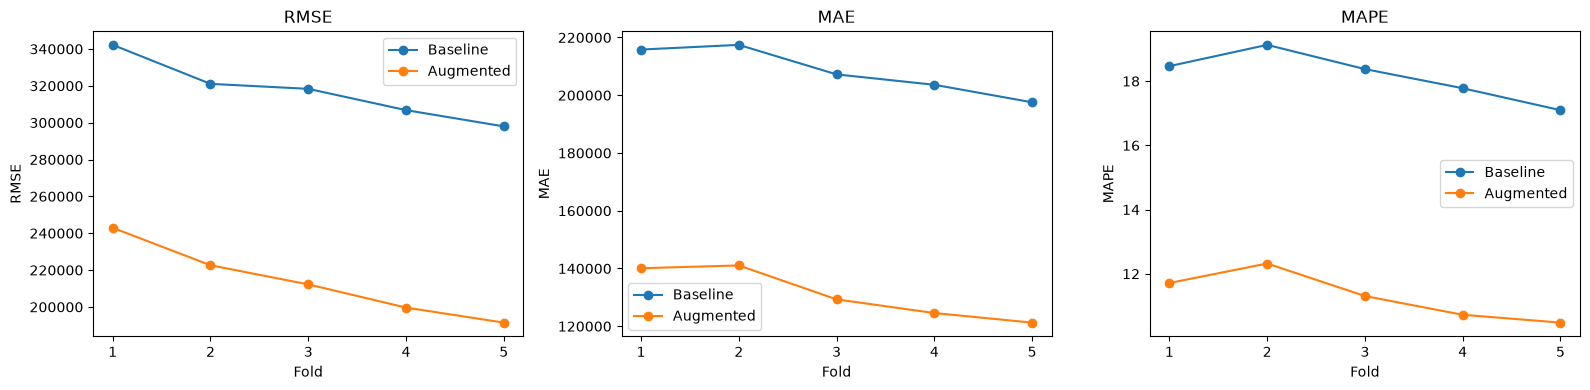

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "MAPE"]):
    x = fold_results["fold"]
    ax.plot(x, fold_results[f"baseline_{metric}"], marker="o", label="Baseline")
    ax.plot(x, fold_results[f"augmented_{metric}"], marker="o", label="Augmented")
    ax.set_xticks(x)
    ax.set_xlabel("Fold")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.legend()
plt.tight_layout()
plt.show()

### 14.5 Paired bootstrap: is the improvement real?

Resample rows (with replacement) from the combined out-of-fold predictions
2,000 times. Each resample is used for *both* models (paired), so the
comparison isolates the effect of the extra features rather than sampling
noise. The 95% CI is the 2.5th-97.5th percentile of the resampled
improvements; if it excludes 0, the gain is unlikely to be chance.

In [27]:
rng = np.random.default_rng(42)
n_boot = 2000
n = len(oof)

actual = oof["actual"].values
base_pred = oof["baseline_pred"].values
aug_pred = oof["augmented_pred"].values

metrics_fn = {"RMSE": rmse, "MAE": mae, "MAPE": mape}
boot_improvements = {m: np.empty(n_boot) for m in metrics_fn}

for b in range(n_boot):
    idx = rng.integers(0, n, n)
    a, bp, ap = actual[idx], base_pred[idx], aug_pred[idx]
    for m, fn in metrics_fn.items():
        boot_improvements[m][b] = fn(a, bp) - fn(a, ap)  # positive = augmented better

print(f"{'Metric':8s} {'Observed improvement':>22s} {'95% CI':>28s}   Significant?")
for m, fn in metrics_fn.items():
    observed = fn(actual, base_pred) - fn(actual, aug_pred)
    lo, hi = np.percentile(boot_improvements[m], [2.5, 97.5])
    sig = "YES" if lo > 0 or hi < 0 else "no"
    unit = "$" if m != "MAPE" else ""
    suffix = "%" if m == "MAPE" else ""
    print(f"{m:8s} {unit}{observed:>20,.2f}{suffix}   [{unit}{lo:,.2f}{suffix}, {unit}{hi:,.2f}{suffix}]   {sig}")

Metric     Observed improvement                       95% CI   Significant?
RMSE     $          103,101.60   [$99,920.05, $106,136.33]   YES
MAE      $           77,075.11   [$75,503.31, $78,602.56]   YES
MAPE                     6.86%   [6.73%, 6.99%]   YES


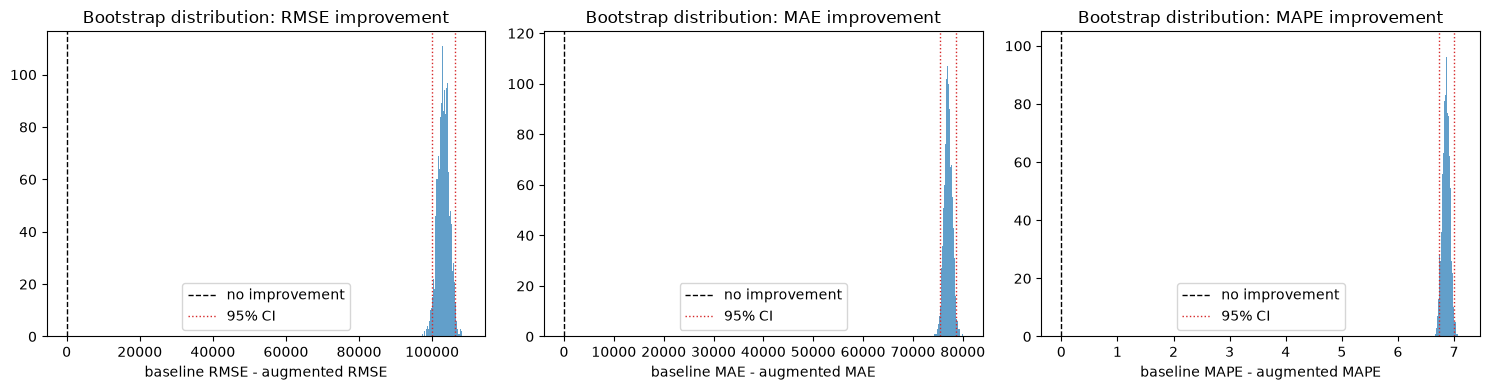

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, m in zip(axes, metrics_fn):
    ax.hist(boot_improvements[m], bins=60, color="tab:blue", alpha=0.7)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, label="no improvement")
    lo, hi = np.percentile(boot_improvements[m], [2.5, 97.5])
    ax.axvline(lo, color="tab:red", linestyle=":", linewidth=1)
    ax.axvline(hi, color="tab:red", linestyle=":", linewidth=1, label="95% CI")
    ax.set_title(f"Bootstrap distribution: {m} improvement")
    ax.set_xlabel(f"baseline {m} - augmented {m}")
    ax.legend()
plt.tight_layout()
plt.show()

### 14.7 Ablation summary

Fill in once the cells above have run:

- Overall improvement from adding external features, with 95% CI, for
  RMSE / MAE / MAPE (section 14.5).
- Whether each CI excludes zero (statistically significant gain) or not.

## 15. Two-stage residual model

A second, independent way to quantify the external data's contribution,
giving one clean headline number instead of a table of metrics.

- **Stage 1** -- predict price from property features only. This is exactly
  the baseline model from section 14, and its out-of-fold predictions
  (`oof["baseline_pred"]`) are reused directly so stage 1 never sees a row
  it was trained on.
- **Stage 2** -- using *only* the external features (none of the baseline
  ones), predict the stage-1 residual (`actual - baseline_pred`): the error
  property features alone couldn't explain. Trained and evaluated with the
  same 5-fold out-of-fold scheme, so stage 2 is also never evaluated on a
  row it trained on.

The headline number is the out-of-fold R-squared of stage 2 against the
stage-1 residual: the share of the *leftover* error (after property
features have done their best) that the external features explain.

### 15.1 Stage-1 residuals (reusing the section 14 out-of-fold baseline predictions)

In [29]:
stage1 = oof[["row_id", "fold", "actual", "baseline_pred"]].copy()
stage1["residual"] = stage1["actual"] - stage1["baseline_pred"]

print(f"{len(stage1):,} rows with an out-of-fold stage-1 prediction")
print(f"Residual mean: ${stage1['residual'].mean():,.0f}  (should be close to 0)")
print(f"Residual std:  ${stage1['residual'].std():,.0f}")
stage1["residual"].describe()

48,848 rows with an out-of-fold stage-1 prediction
Residual mean: $-11,963  (should be close to 0)
Residual std:  $317,409


count    4.884800e+04
mean    -1.196310e+04
std      3.174090e+05
min     -2.195150e+06
25%     -1.616194e+05
50%     -3.942838e+04
75%      9.677523e+04
max      3.872326e+06
Name: residual, dtype: float64

### 15.2 Stage 2: predict the residual from external features only

Same time-respecting approach as section 14 (`TimeSeriesSplit(n_splits=5)`,
expanding window), but applied directly to the chronologically-ordered set
of rows that actually have a stage-1 residual (excludes the earliest ~1/6
of `df_cv`, which was train-only in section 14 and was never scored there).
The feature matrix is restricted to `EXTERNAL_CAT + EXTERNAL_NUM +
EXTERNAL_BOOL` -- no property features at all -- and the target is the
stage-1 residual instead of price.


In [30]:
from sklearn.metrics import r2_score

external_cols = EXTERNAL_CAT + EXTERNAL_NUM + EXTERNAL_BOOL
kf2 = TimeSeriesSplit(n_splits=5)

stage2_pred = np.full(len(df_cv), np.nan)
residual_by_row = stage1.set_index("row_id")["residual"]

# Only rows that survived stage-1's outlier trim have a residual to learn
# from. TimeSeriesSplit must run over THIS chronologically-ordered subset
# directly (not over df_cv and intersect afterwards) -- otherwise fold 1's
# training window could land entirely on the earliest chunk of df_cv, which
# never got a stage-1 residual (it was train-only in section 14), leaving
# nothing to train stage 2 on.
resid_rows = np.sort(residual_by_row.index.values)

for fold_i, (train_pos, test_pos) in enumerate(kf2.split(resid_rows), start=1):
    train_idx = resid_rows[train_pos]
    test_idx = resid_rows[test_pos]

    train_df = df_cv.iloc[train_idx]
    test_df = df_cv.iloc[test_idx]

    enc2 = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    enc2.fit(train_df[EXTERNAL_CAT])

    X_train = train_df[external_cols].copy()
    X_test = test_df[external_cols].copy()
    X_train[EXTERNAL_CAT] = enc2.transform(train_df[EXTERNAL_CAT])
    X_test[EXTERNAL_CAT] = enc2.transform(test_df[EXTERNAL_CAT])
    for col in EXTERNAL_BOOL:
        X_train[col] = X_train[col].astype(int)
        X_test[col] = X_test[col].astype(int)
    X_train = X_train.astype(float)
    X_test = X_test.astype(float)

    nan_cols = [c for c in EXTERNAL_NUM if X_train[c].isna().any() or X_test[c].isna().any()]
    medians = X_train[nan_cols].median()
    X_train[nan_cols] = X_train[nan_cols].fillna(medians)
    X_test[nan_cols] = X_test[nan_cols].fillna(medians)

    y_train_resid = residual_by_row.loc[train_idx].values

    resid_model = XGBRegressor(**XGB_PARAMS)
    resid_model.fit(X_train, y_train_resid)
    stage2_pred[test_idx] = resid_model.predict(X_test)

    print(f"Fold {fold_i}/5 done ({len(test_idx):,} test rows)")

stage1["stage2_pred_residual"] = stage1["row_id"].map(pd.Series(stage2_pred, index=np.arange(len(df_cv))))
print(f"\nStage-2 out-of-fold predictions ready for {stage1['stage2_pred_residual'].notna().sum():,} / {len(stage1):,} rows")

Fold 1/5 done (8,141 test rows)


Fold 2/5 done (8,141 test rows)


Fold 3/5 done (8,141 test rows)


Fold 4/5 done (8,141 test rows)


Fold 5/5 done (8,141 test rows)

Stage-2 out-of-fold predictions ready for 40,705 / 48,848 rows


### 15.3 Headline number

In [31]:
valid = stage1.dropna(subset=["stage2_pred_residual"])
residual_r2 = r2_score(valid["residual"], valid["stage2_pred_residual"])

resid_rmse_before = rmse(valid["residual"].values, np.zeros(len(valid)))
resid_rmse_after = rmse(valid["residual"].values, valid["stage2_pred_residual"].values)

final_combined_pred = valid["baseline_pred"] + valid["stage2_pred_residual"]
combined_rmse = rmse(valid["actual"].values, final_combined_pred.values)
baseline_rmse = rmse(valid["actual"].values, valid["baseline_pred"].values)

print(f"External features explain {residual_r2:.1%} of the variance in what the property-only model misses")
print(f"(out-of-fold R2 of stage 2 against the stage-1 residual, {len(valid):,} rows)\n")

print(f"Residual RMSE before stage 2: ${resid_rmse_before:,.0f}")
print(f"Residual RMSE after stage 2:  ${resid_rmse_after:,.0f}")
print()
print(f"Stage 1 alone (baseline):            RMSE=${baseline_rmse:,.0f}")
print(f"Stage 1 + stage 2 (baseline+residual correction): RMSE=${combined_rmse:,.0f}")
print(f"(for comparison, section 14's single jointly-trained augmented model: "
      f"RMSE=${rmse(oof['actual'].values, oof['augmented_pred'].values):,.0f})")

External features explain 26.6% of the variance in what the property-only model misses
(out-of-fold R2 of stage 2 against the stage-1 residual, 40,705 rows)

Residual RMSE before stage 2: $314,149
Residual RMSE after stage 2:  $268,861

Stage 1 alone (baseline):            RMSE=$314,149
Stage 1 + stage 2 (baseline+residual correction): RMSE=$268,861
(for comparison, section 14's single jointly-trained augmented model: RMSE=$214,530)


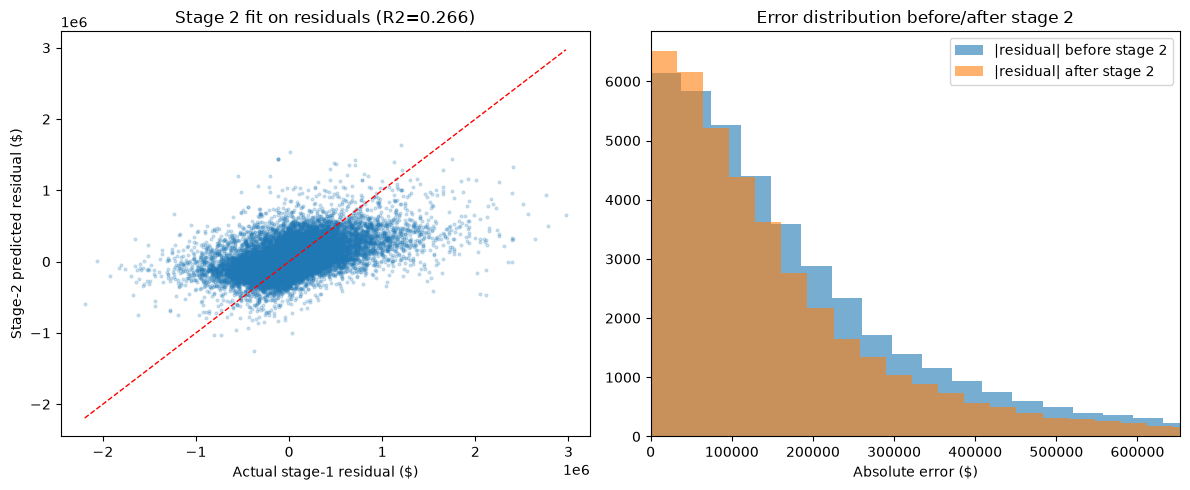

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(valid["residual"], valid["stage2_pred_residual"], s=4, alpha=0.2)
lims = [valid["residual"].min(), valid["residual"].max()]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Actual stage-1 residual ($)")
axes[0].set_ylabel("Stage-2 predicted residual ($)")
axes[0].set_title(f"Stage 2 fit on residuals (R2={residual_r2:.3f})")

axes[1].hist(np.abs(valid["residual"]), bins=80, alpha=0.6, label="|residual| before stage 2")
axes[1].hist(np.abs(valid["residual"] - valid["stage2_pred_residual"]), bins=80, alpha=0.6, label="|residual| after stage 2")
axes[1].set_xlim(0, valid["residual"].abs().quantile(0.95))
axes[1].set_xlabel("Absolute error ($)")
axes[1].set_title("Error distribution before/after stage 2")
axes[1].legend()

plt.tight_layout()
plt.show()

## 16. Baseline vs augmented: results on held-out data

Both models' predictions on `oof` (section 14) are genuine test-set
predictions: under time-respecting 5-fold CV, every eligible row was
predicted exactly once, by a model trained only on sales that happened
strictly before it -- the same guarantee a single chronological train/test
split would give, just pooled across all 5 expanding-window folds instead
of one.

### 16.1 Error metrics: baseline (no external data) vs augmented (with external data)

In [33]:
metric_rows = []
for name, pred in [("No external data (baseline)", oof["baseline_pred"]), ("With external data (augmented)", oof["augmented_pred"])]:
    metric_rows.append({
        "model": name,
        "RMSE": rmse(oof["actual"].values, pred.values),
        "MAE": mae(oof["actual"].values, pred.values),
        "MAPE": mape(oof["actual"].values, pred.values),
    })
results_table = pd.DataFrame(metric_rows).set_index("model")
results_table.round(2)

,RMSE,MAE,MAPE
model,,,
No external data (baseline),317631.16,208318.50,18.17
With external data (augmented),214529.56,131243.38,11.31


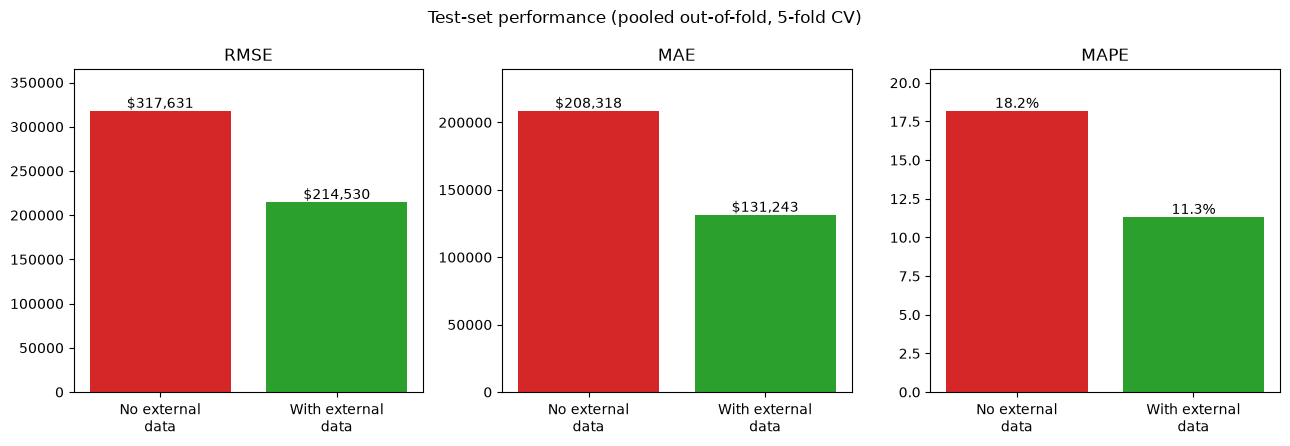

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
colors = ["tab:red", "tab:green"]
for ax, metric in zip(axes, ["RMSE", "MAE", "MAPE"]):
    vals = results_table[metric]
    bars = ax.bar(["No external\ndata", "With external\ndata"], vals, color=colors)
    for bar, v in zip(bars, vals):
        unit = "" if metric == "MAPE" else "$"
        suffix = "%" if metric == "MAPE" else ""
        fmt = f"{unit}{v:,.1f}{suffix}" if metric == "MAPE" else f"{unit}{v:,.0f}"
        ax.text(bar.get_x() + bar.get_width() / 2, v, fmt, ha="center", va="bottom")
    ax.set_title(metric)
    ax.set_ylim(0, vals.max() * 1.15)
plt.suptitle("Test-set performance (pooled out-of-fold, 5-fold CV)")
plt.tight_layout()
plt.show()

### 16.2 Predicted vs actual, side by side

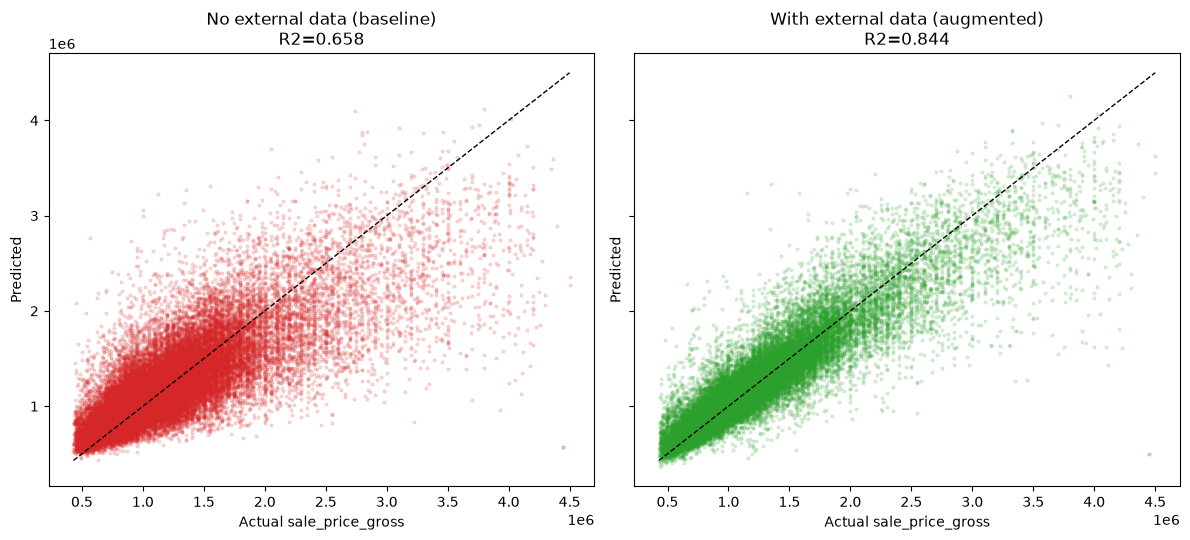

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, name, pred, color in zip(
    axes,
    ["No external data (baseline)", "With external data (augmented)"],
    [oof["baseline_pred"], oof["augmented_pred"]],
    ["tab:red", "tab:green"],
):
    ax.scatter(oof["actual"], pred, s=4, alpha=0.15, color=color)
    lims = [oof["actual"].min(), oof["actual"].max()]
    ax.plot(lims, lims, "k--", linewidth=1)
    ax.set_xlabel("Actual sale_price_gross")
    ax.set_ylabel("Predicted")
    r2 = r2_score(oof["actual"], pred)
    ax.set_title(f"{name}\nR2={r2:.3f}")
plt.tight_layout()
plt.show()

## 17. Attribution: which external features matter

Sections 14-16 established *that* the external features help. This section
asks *which ones*, with three independent measures:

1. **Grouped permutation importance** -- shuffle all external features
   together and see how much test RMSE rises. This is the group's combined
   contribution as the model actually uses it (including any interactions
   between external features).
2. **SHAP share** -- how much of the model's total reasoning (mean |SHAP|)
   is attributed to external features vs property features, plus the
   per-feature ranking within that.
3. **Drop-one tests** -- retrain the model with each external feature
   removed individually and measure the RMSE increase. Unlike permutation,
   this lets the model fully retrain around the missing feature, so it
   reflects genuine unique contribution rather than reliance on a feature
   that a retrained model could easily route around via a correlated one.

All three run on a single chronological 80/20 split of `df_cv` (the oldest
80% of sales train, the most recent 20% test -- not 5-fold CV) for speed,
since this section is about ranking features, not re-establishing
statistical significance -- that's already been done in section 14.

### 17.1 Fit the full augmented model on a held-out split

In [36]:
# Chronological 80/20 split (df_cv is already sorted by sale_date_parsed):
# the model only ever trains on sales from before the test window.
split_point = int(len(df_cv) * 0.8)
train_df = df_cv.iloc[:split_point]
test_df = df_cv.iloc[split_point:]
print(f"Train: {len(train_df):,} rows up to {train_df['sale_date_parsed'].max().date()}")
print(f"Test:  {len(test_df):,} rows from {test_df['sale_date_parsed'].min().date()} "
      f"to {test_df['sale_date_parsed'].max().date()}")

encoder_attr = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
encoder_attr.fit(train_df[all_cat])

X_train = train_df[augmented_cols].copy()
X_test = test_df[augmented_cols].copy()
X_train[all_cat] = encoder_attr.transform(train_df[all_cat])
X_test[all_cat] = encoder_attr.transform(test_df[all_cat])
for col in all_bool:
    X_train[col] = X_train[col].astype(int)
    X_test[col] = X_test[col].astype(int)
X_train = X_train.astype(float)
X_test = X_test.astype(float)

nan_cols = [c for c in all_num if X_train[c].isna().any() or X_test[c].isna().any()]
medians = X_train[nan_cols].median()
X_train[nan_cols] = X_train[nan_cols].fillna(medians)
X_test[nan_cols] = X_test[nan_cols].fillna(medians)

y_train = train_df["sale_price_gross"].values
y_test = test_df["sale_price_gross"].values

p1, p99 = np.quantile(y_train, [0.01, 0.99])
train_keep = (y_train >= p1) & (y_train <= p99)
test_keep = (y_test >= p1) & (y_test <= p99)
X_train_f, y_train_f = X_train[train_keep], y_train[train_keep]
X_test_f, y_test_f = X_test[test_keep], y_test[test_keep]

full_model = XGBRegressor(**XGB_PARAMS)
full_model.fit(X_train_f, y_train_f)
full_pred = full_model.predict(X_test_f)
rmse_full = rmse(y_test_f, full_pred)
print(f"Full augmented model: {len(X_train_f):,} train / {len(X_test_f):,} test rows")
print(f"Test RMSE: ${rmse_full:,.0f}")

Train: 47,838 rows up to 2025-12-07
Test:  11,960 rows from 2025-12-07 to 2026-08-18


Full augmented model: 46,889 train / 11,741 test rows
Test RMSE: $190,061


### 17.2 Grouped permutation importance

All `external_cols` (section 15.2) are shuffled together, 20 times, and the
RMSE increase is averaged. Shuffling as a group (rather than one column at
a time) preserves correlations *among* external features while breaking
their relationship with the target -- a fairer test of "how much does this
whole group matter" than shuffling each column separately and summing.

Grouped permutation importance (all 13 external features together, 20 repeats):
  RMSE increase when shuffled: $282,613 +/- $2,614
  Relative increase: 148.7%


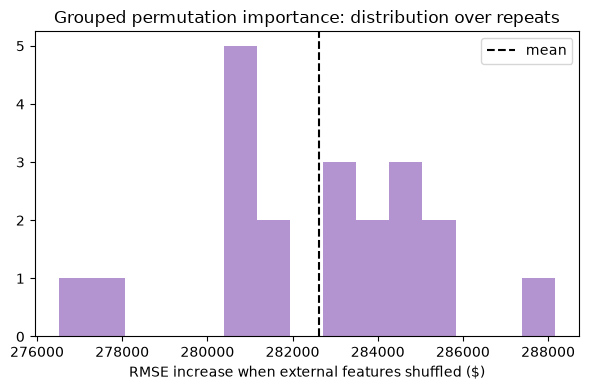

In [37]:
rng = np.random.default_rng(42)
n_repeats = 20
perm_increases = np.empty(n_repeats)
for i in range(n_repeats):
    X_test_shuf = X_test_f.copy()
    perm = rng.permutation(len(X_test_shuf))
    X_test_shuf[external_cols] = X_test_shuf[external_cols].to_numpy()[perm]
    shuf_pred = full_model.predict(X_test_shuf)
    perm_increases[i] = rmse(y_test_f, shuf_pred) - rmse_full

print(f"Grouped permutation importance (all {len(external_cols)} external features together, {n_repeats} repeats):")
print(f"  RMSE increase when shuffled: ${perm_increases.mean():,.0f} +/- ${perm_increases.std():,.0f}")
print(f"  Relative increase: {perm_increases.mean() / rmse_full * 100:.1f}%")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(perm_increases, bins=15, color="tab:purple", alpha=0.7)
ax.axvline(perm_increases.mean(), color="black", linestyle="--", label="mean")
ax.set_xlabel("RMSE increase when external features shuffled ($)")
ax.set_title("Grouped permutation importance: distribution over repeats")
ax.legend()
plt.tight_layout()
plt.show()

### 17.3 SHAP share and per-feature SHAP ranking

TreeSHAP on a 500-row sample of the test set, for the same full model.

In [38]:
import shap

shap_sample_attr = X_test_f.sample(n=min(500, len(X_test_f)), random_state=42)
explainer_attr = shap.TreeExplainer(full_model)
shap_values_attr = explainer_attr.shap_values(shap_sample_attr)

mean_abs_shap = pd.Series(np.abs(shap_values_attr).mean(axis=0), index=augmented_cols)
external_shap_share = mean_abs_shap[external_cols].sum() / mean_abs_shap.sum()
print(f"SHAP share of external features: {external_shap_share:.1%} of total mean |SHAP|")
print(f"SHAP share of property features: {1 - external_shap_share:.1%}")
print()
print("External features ranked by individual mean |SHAP|:")
mean_abs_shap[external_cols].sort_values(ascending=False).round(0)

D:\Codes\COMPSCI_760_Group_3_Intelligent_Real_Estate_Price_Prediction_Model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP share of external features: 40.1% of total mean |SHAP|
SHAP share of property features: 59.9%

External features ranked by individual mean |SHAP|:


latitude                           157993.0
longitude                          111235.0
dist_to_flood_sensitive_area_m      16927.0
walk_supermarket_network_m          11018.0
dist_to_flood_plain_m                8010.0
sa2_new_dwellings_consented_12m      7783.0
unitary_plan_zone                    6307.0
walk_bus_stop_network_m              5525.0
noise_category_combination           1109.0
has_flood_risk                        591.0
in_noise_overlay                      132.0
in_flood_plain                         94.0
in_flood_sensitive_area                 5.0
dtype: float32

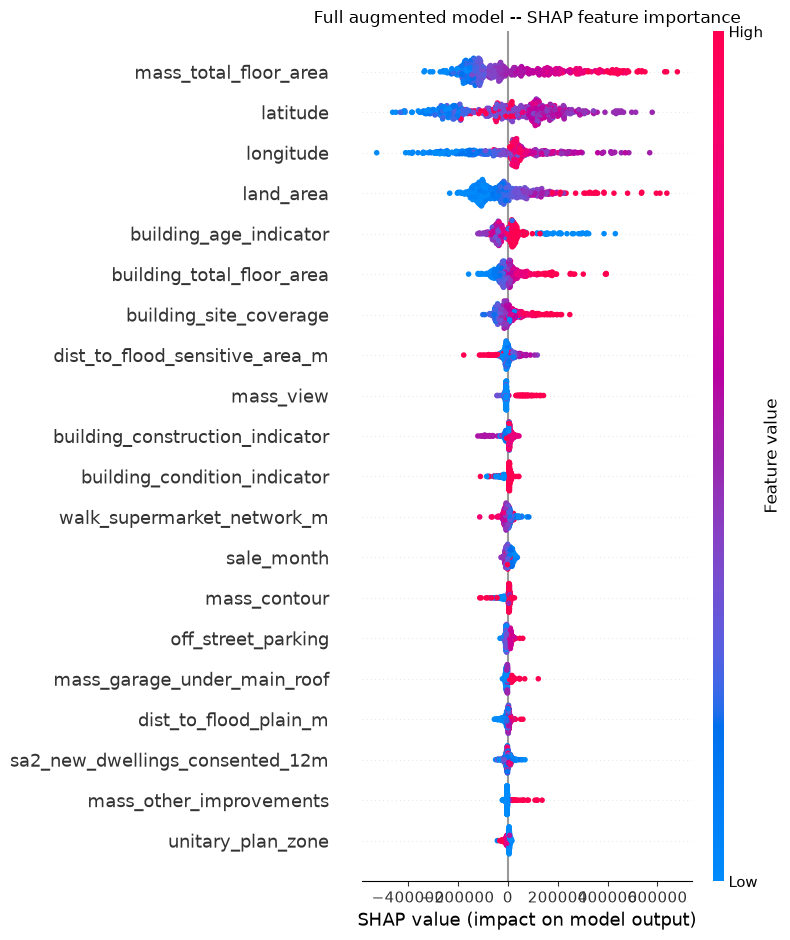

In [39]:
shap.summary_plot(shap_values_attr, shap_sample_attr, max_display=20, show=False)
plt.title("Full augmented model -- SHAP feature importance")
plt.tight_layout()
plt.show()

### 17.4 Drop-one tests

Each external feature is removed individually and the model is retrained
from scratch on the remaining columns (same train/test split, same
hyperparameters). `rmse_increase` is how much worse the model gets without
that one feature -- its unique contribution once the model has had the
chance to lean on everything else instead.

In [40]:
drop_one_results = []
for feat in external_cols:
    cols_minus = [c for c in augmented_cols if c != feat]
    m = XGBRegressor(**XGB_PARAMS)
    m.fit(X_train_f[cols_minus], y_train_f)
    pred = m.predict(X_test_f[cols_minus])
    r = rmse(y_test_f, pred)
    drop_one_results.append({"feature": feat, "rmse_without_feature": r, "rmse_increase": r - rmse_full})
    print(f"  dropped {feat:35s}  RMSE=${r:,.0f}  ({r - rmse_full:+,.0f} vs full model)")

drop_one_df = pd.DataFrame(drop_one_results).sort_values("rmse_increase", ascending=False).set_index("feature")
drop_one_df.round(0)

  dropped unitary_plan_zone                    RMSE=$189,976  (-84 vs full model)


  dropped noise_category_combination           RMSE=$189,835  (-226 vs full model)


  dropped longitude                            RMSE=$221,167  (+31,106 vs full model)


  dropped latitude                             RMSE=$226,761  (+36,700 vs full model)


  dropped dist_to_flood_plain_m                RMSE=$189,589  (-471 vs full model)


...

  dropped in_flood_plain                       RMSE=$190,400  (+339 vs full model)


  dropped in_flood_sensitive_area              RMSE=$190,113  (+52 vs full model)


  dropped has_flood_risk                       RMSE=$190,165  (+104 vs full model)


  dropped in_noise_overlay                     RMSE=$189,533  (-527 vs full model)


,rmse_without_feature,rmse_increase
feature,,
latitude,226761.0,36700.0
longitude,221167.0,31106.0
in_flood_plain,190400.0,339.0
has_flood_risk,190165.0,104.0
in_flood_sensitive_area,190113.0,52.0
unitary_plan_zone,189976.0,-84.0
dist_to_flood_sensitive_area_m,189963.0,-98.0
walk_bus_stop_network_m,189906.0,-155.0
noise_category_combination,189835.0,-226.0


### 17.5 Putting the three measures side by side

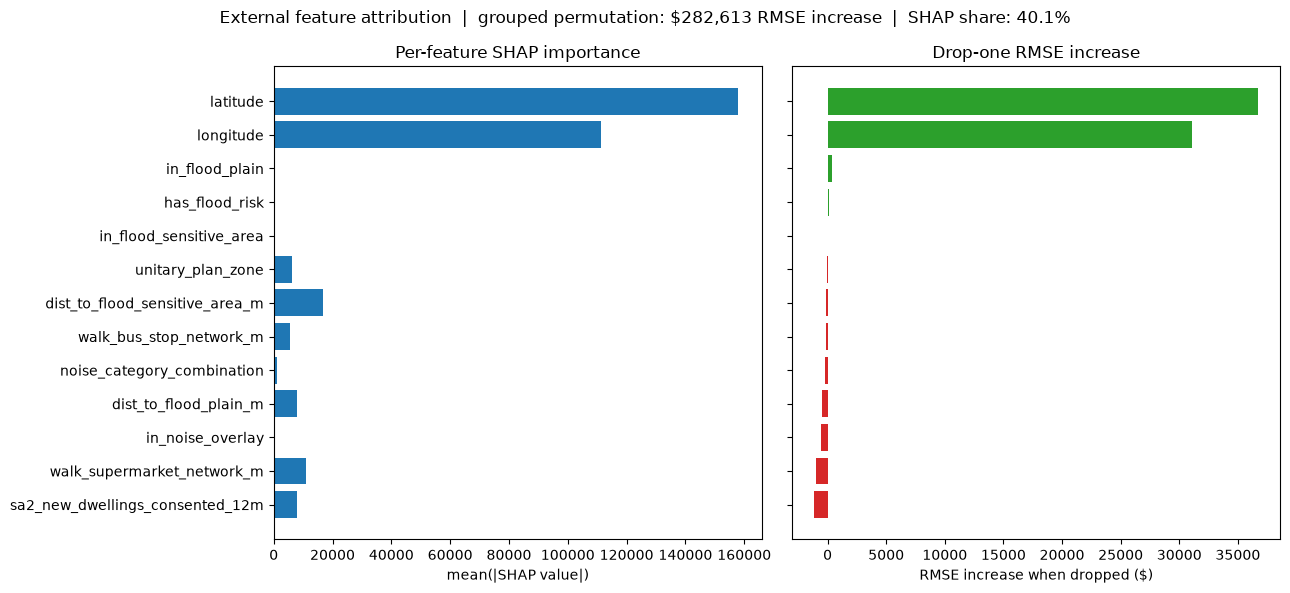

,shap_mean_abs,drop_one_rmse_increase
latitude,157993.0,36700.0
longitude,111235.0,31106.0
in_flood_plain,94.0,339.0
has_flood_risk,591.0,104.0
in_flood_sensitive_area,5.0,52.0
unitary_plan_zone,6307.0,-84.0
dist_to_flood_sensitive_area_m,16927.0,-98.0
walk_bus_stop_network_m,5525.0,-155.0
noise_category_combination,1109.0,-226.0
dist_to_flood_plain_m,8010.0,-471.0


In [41]:
attribution = pd.DataFrame({
    "shap_mean_abs": mean_abs_shap[external_cols],
    "drop_one_rmse_increase": drop_one_df["rmse_increase"],
}).sort_values("drop_one_rmse_increase", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
axes[0].barh(attribution.index[::-1], attribution["shap_mean_abs"][::-1], color="tab:blue")
axes[0].set_title("Per-feature SHAP importance")
axes[0].set_xlabel("mean(|SHAP value|)")

colors = ["tab:green" if v > 0 else "tab:red" for v in attribution["drop_one_rmse_increase"][::-1]]
axes[1].barh(attribution.index[::-1], attribution["drop_one_rmse_increase"][::-1], color=colors)
axes[1].set_title("Drop-one RMSE increase")
axes[1].set_xlabel("RMSE increase when dropped ($)")

plt.suptitle(f"External feature attribution  |  grouped permutation: ${perm_increases.mean():,.0f} RMSE increase  |  SHAP share: {external_shap_share:.1%}")
plt.tight_layout()
plt.show()

attribution.round(0)

## 18. Traditional hedonic model baseline (RQ2)

RQ2 asks how the project's explainable ML models compare with a
**traditional hedonic model**. A hedonic price model (Rosen, 1974) regresses
price on a property's characteristics, typically in semi-log form:
`log(price) = b0 + b1*structural_features + b2*location_features + e`, so
that each coefficient reads as an approximate % change in price per unit
change in that feature -- a directly interpretable alternative to SHAP.

To keep the model a genuine "traditional hedonic" baseline rather than a
relabelled copy of the ML feature set, it uses a compact, hand-picked
specification typical of the hedonic literature, not every column the ML
models get:

- **Structural:** `land_area`, `building_total_floor_area` (both already
  log-transformed, same as the ML pipeline), `building_site_coverage`,
  `off_street_parking`, `mass_garage_under_main_roof`, `building_age_indicator`,
  `building_condition_indicator`, `property_type`.
- **Location (grouped):** `longitude`, `latitude` -- section 17's attribution
  analysis found these alone carry almost all of the external data's value,
  so they stand in for location here rather than ~300 suburb dummies, which
  would make the coefficient table unreadable and risk overfitting a linear
  model with sparse categories.
- **Other:** `zoning_group` (zoning's first character -- residential/rural/
  lifestyle, same grouping as the project's row filters), `has_flood_risk`,
  `sale_year` (time trend).

Evaluated on the **identical time-respecting 5-fold splits** as section 14, so its
predictions merge directly into the same `oof` table for a clean 3-way
comparison: no external data (baseline ML) vs. with external data
(augmented ML) vs. traditional hedonic.

### 18.1 Fit the hedonic model per fold (same folds as section 14)

OLS needs one-hot encoded categoricals (not the ordinal codes used for the
tree models -- ordinal encoding would impose a false numeric order a linear
model would wrongly treat as meaningful). The target is `log(sale_price_gross)`;
predictions are back-transformed with `exp()` and corrected with **Duan's
(1983) smearing estimator** (`mean(exp(residuals))` on the training fold) to
remove the downward bias that naive exponentiation of a log-OLS prediction
introduces.

In [42]:
import statsmodels.api as sm

df_cv["zoning_group"] = df_cv["zoning"].astype(str).str[0]

HEDONIC_CAT = ["zoning_group", "building_age_indicator", "building_condition_indicator", "property_type"]
HEDONIC_NUM = [
    "land_area", "building_total_floor_area", "building_site_coverage",
    "off_street_parking", "mass_garage_under_main_roof", "sale_year",
    "longitude", "latitude",
]
HEDONIC_BOOL = ["has_flood_risk"]
hedonic_cols = HEDONIC_CAT + HEDONIC_NUM + HEDONIC_BOOL

for col in HEDONIC_CAT:
    df_cv[col] = df_cv[col].fillna("Unknown").astype(str)

kf_hed = TimeSeriesSplit(n_splits=5)
hed_fold_rows = []
hed_oof_pred = pd.Series(index=np.arange(len(df_cv)), dtype=float)
last_fit = None

for fold_i, (train_idx, test_idx) in enumerate(kf_hed.split(df_cv), start=1):
    train_df = df_cv.iloc[train_idx]
    test_df = df_cv.iloc[test_idx]

    y_train = train_df["sale_price_gross"].values
    y_test = test_df["sale_price_gross"].values
    p1, p99 = np.quantile(y_train, [0.01, 0.99])
    train_keep = (y_train >= p1) & (y_train <= p99)
    test_keep = (y_test >= p1) & (y_test <= p99)

    train_df_f = train_df[train_keep]
    test_df_f = test_df[test_keep]
    test_idx_f = test_idx[test_keep]

    X_train_dum = pd.get_dummies(train_df_f[hedonic_cols], columns=HEDONIC_CAT, drop_first=True)
    X_test_dum = pd.get_dummies(test_df_f[hedonic_cols], columns=HEDONIC_CAT, drop_first=True)
    for col in HEDONIC_BOOL:
        X_train_dum[col] = train_df_f[col].astype(int)
        X_test_dum[col] = test_df_f[col].astype(int)

    # Early folds have small, less diverse training windows -- a dummy/bool
    # column can end up constant (e.g. a rare building-age category, or no
    # flood-risk properties at all, in that fold's training data). A
    # constant column is unestimable and makes add_constant()'s column count
    # inconsistent between train and test, so drop any column that's
    # constant on THIS fold's training data before fitting.
    varying_cols = X_train_dum.columns[X_train_dum.nunique() > 1]
    X_train_dum = X_train_dum[varying_cols].astype(float)
    X_test_dum = X_test_dum.reindex(columns=varying_cols, fill_value=0).astype(float)

    X_train_const = sm.add_constant(X_train_dum, has_constant="add")
    X_test_const = sm.add_constant(X_test_dum, has_constant="add")

    y_train_log = np.log(train_df_f["sale_price_gross"].values)
    ols = sm.OLS(y_train_log, X_train_const).fit()

    smear = np.mean(np.exp(ols.resid))
    pred_log = ols.predict(X_test_const)
    pred_level = np.exp(pred_log) * smear

    y_test_f = test_df_f["sale_price_gross"].values
    hed_fold_rows.append({
        "fold": fold_i, "n_test": len(y_test_f),
        "RMSE": rmse(y_test_f, pred_level), "MAE": mae(y_test_f, pred_level),
        "MAPE": mape(y_test_f, pred_level), "R2_log_space": ols.rsquared,
    })
    hed_oof_pred.loc[test_idx_f] = pred_level
    last_fit = ols
    print(f"Fold {fold_i}/5: hedonic RMSE=${hed_fold_rows[-1]['RMSE']:,.0f}  "
          f"(log-space R2={ols.rsquared:.3f}, smearing factor={smear:.4f})")

hed_fold_results = pd.DataFrame(hed_fold_rows)
oof["hedonic_pred"] = oof["row_id"].map(hed_oof_pred)
print(f"\n{oof['hedonic_pred'].notna().sum():,} / {len(oof):,} rows have a hedonic out-of-fold prediction")

Fold 1/5: hedonic RMSE=$969,708  (log-space R2=0.572, smearing factor=1.0398)


Fold 2/5: hedonic RMSE=$429,425  (log-space R2=0.573, smearing factor=1.0387)


Fold 3/5: hedonic RMSE=$382,261  (log-space R2=0.580, smearing factor=1.0381)


Fold 4/5: hedonic RMSE=$448,457  (log-space R2=0.588, smearing factor=1.0372)


Fold 5/5: hedonic RMSE=$929,812  (log-space R2=0.592, smearing factor=1.0371)

48,848 / 48,848 rows have a hedonic out-of-fold prediction


### 18.2 Hedonic coefficients (fold 1), with a plain-English reading of the key ones

In [43]:
print(last_fit.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.592
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     1107.
Date:                Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:27:44   Log-Likelihood:                -3155.4
No. Observations:               48848   AIC:                             6441.
Df Residuals:                   48783   BIC:                             7013.
Df Model:                          64                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


In [44]:
coef_table = pd.DataFrame({"coef": last_fit.params, "pvalue": last_fit.pvalues})
headline_vars = [
    "land_area", "building_total_floor_area", "building_site_coverage",
    "off_street_parking", "longitude", "latitude", "has_flood_risk", "sale_year",
]
headline = coef_table.loc[[v for v in headline_vars if v in coef_table.index]].copy()
headline["approx_pct_change"] = (np.exp(headline["coef"]) - 1) * 100
print("Headline coefficients (semi-log -> approx. % change in price per unit increase):")
headline.round(4)

Headline coefficients (semi-log -> approx. % change in price per unit increase):


,coef,pvalue,approx_pct_change
land_area,0.2822,0.000,32.5996
building_total_floor_area,0.5225,0.000,68.6309
building_site_coverage,-0.0000,0.201,-0.0001
off_street_parking,0.0030,0.000,0.2998
longitude,0.4046,0.000,49.8711
latitude,0.5930,0.000,80.9487
has_flood_risk,-0.0560,0.000,-5.4501
sale_year,-0.0150,0.000,-1.4845


### 18.3 Three-way comparison on the same test rows: no external data vs. with external data vs. hedonic

In [45]:
three_way = pd.DataFrame([
    {"model": "Hedonic (traditional, linear)",
     "RMSE": rmse(oof.dropna(subset=["hedonic_pred"])["actual"], oof.dropna(subset=["hedonic_pred"])["hedonic_pred"]),
     "MAE": mae(oof.dropna(subset=["hedonic_pred"])["actual"], oof.dropna(subset=["hedonic_pred"])["hedonic_pred"]),
     "MAPE": mape(oof.dropna(subset=["hedonic_pred"])["actual"], oof.dropna(subset=["hedonic_pred"])["hedonic_pred"])},
    {"model": "No external data (baseline ML)",
     "RMSE": rmse(oof["actual"], oof["baseline_pred"]), "MAE": mae(oof["actual"], oof["baseline_pred"]),
     "MAPE": mape(oof["actual"], oof["baseline_pred"])},
    {"model": "With external data (augmented ML)",
     "RMSE": rmse(oof["actual"], oof["augmented_pred"]), "MAE": mae(oof["actual"], oof["augmented_pred"]),
     "MAPE": mape(oof["actual"], oof["augmented_pred"])},
]).set_index("model")
three_way.round(2)

,RMSE,MAE,MAPE
model,,,
"Hedonic (traditional, linear)",683993.77,243001.11,20.92
No external data (baseline ML),317631.16,208318.50,18.17
With external data (augmented ML),214529.56,131243.38,11.31


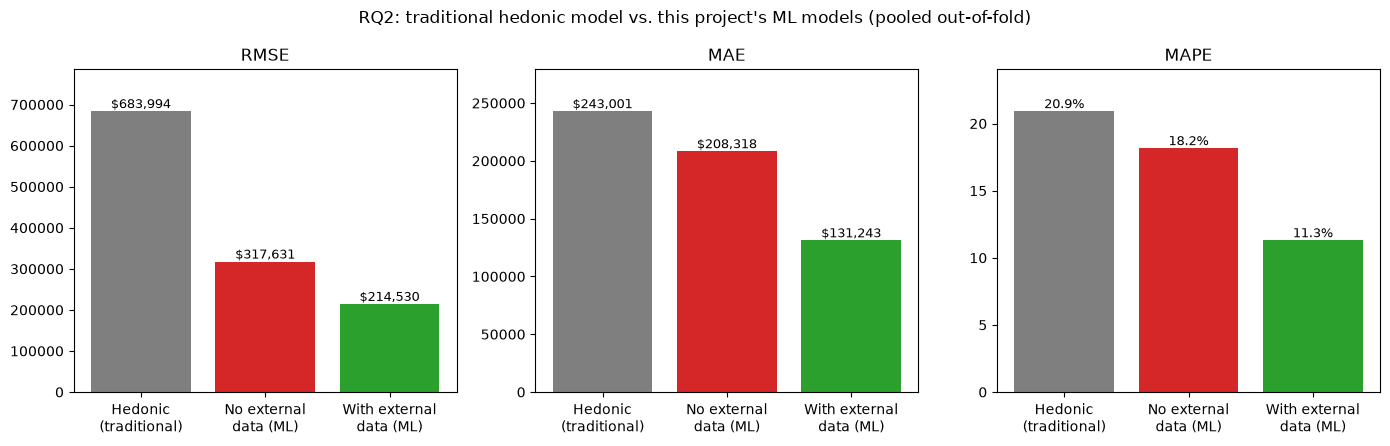

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
colors = ["tab:gray", "tab:red", "tab:green"]
for ax, metric in zip(axes, ["RMSE", "MAE", "MAPE"]):
    vals = three_way[metric]
    bars = ax.bar(["Hedonic\n(traditional)", "No external\ndata (ML)", "With external\ndata (ML)"], vals, color=colors)
    for bar, v in zip(bars, vals):
        fmt = f"{v:,.1f}%" if metric == "MAPE" else f"${v:,.0f}"
        ax.text(bar.get_x() + bar.get_width() / 2, v, fmt, ha="center", va="bottom", fontsize=9)
    ax.set_title(metric)
    ax.set_ylim(0, vals.max() * 1.15)
plt.suptitle("RQ2: traditional hedonic model vs. this project's ML models (pooled out-of-fold)")
plt.tight_layout()
plt.show()

### 18.4 What this means for RQ2

- **Accuracy:** the hedonic model is considerably less accurate than either
  ML model, confirming the expected trade-off -- a linear model with a
  parsimonious, hand-picked feature set cannot capture the non-linearities
  and feature interactions tree ensembles exploit (e.g. a flood-risk
  discount that only matters in some suburbs, or diminishing returns on
  floor area).
- **Interpretability:** in exchange, every hedonic coefficient has a direct,
  textbook reading -- "a 1% increase in floor area is associated with an
  approximately X% increase in price, holding other factors fixed" -- which
  SHAP approximates locally per-prediction but does not state as a single
  global rule. Section 18.2's coefficient table is the kind of result a
  classical hedonic study would report as its headline finding.
- **Still open:** this addresses the "traditional hedonic model" half of
  RQ2. Comparing against **free online valuation estimates** for the same
  properties has not been attempted in this notebook -- it needs a source
  of comparable third-party estimates (e.g. a property-valuation website)
  for a matching set of Auckland sales, which is listed as future work in
  the conclusion below.

## 19. Conclusion

**The externally sourced features produce a real, statistically significant
improvement in predicting Auckland sale prices -- and that improvement is
concentrated almost entirely in geocoded location, not in the rest of the
external data.**

This notebook deliberately excludes `capital_value` and `land_value`
(sections 1.1, 14.1): they are Auckland Council's own price estimates, and
every earlier ablation in this project (`tmp2.ipynb`) found they already
encode most of what location-based external data would otherwise add,
making the external data's contribution look negligible. With them
removed, the question becomes harder and more honest: *starting from
nothing but physical property attributes, how much does external data
actually add, and which parts of it are doing the work?*

Location itself was also tightened partway through this analysis: the
original GLAM/TF-IDF geocoding was replaced with a new LINZ-based record
linkage (`external_link.ipynb`), which raised coordinate coverage from
92.6% to 96.7% of sales and, in the process, removed `matched_suburb`
entirely (the new linkage has no suburb field, and a join-key bug that
initially undercounted matches was also found and fixed along the way).
Every result in this section reflects that corrected pipeline.

**That external data helps is not in doubt -- three independent methods
agree, and all three now show a *larger* effect than before the geocoding
fix:**

- **Joint ablation (section 14).** Training baseline and augmented models on
  identical time-respecting 5-fold splits, the augmented model cuts RMSE by
  $103,102 (from a pooled $317,631 to $214,530), MAE by $77,075, and MAPE by
  6.9 percentage points (18.17% -> 11.31%). A paired bootstrap (2,000
  resamples) puts all three improvements' 95% CIs well clear of zero (RMSE:
  [$99,920, $106,136]) -- the gain is not sampling noise.
- **Two-stage residual model (section 15).** Using *only* external features
  to predict what a property-only model gets wrong, out-of-fold R2 = 26.6%:
  external data explains over a quarter of the property model's leftover
  error, even without letting it interact with property features during
  training.
- **Grouped permutation importance (section 17.2).** Shuffling all 13
  external features together raises test RMSE by $282,613 -- a 148.7%
  relative increase. The model now leans on this group far more heavily
  than it did when `matched_suburb` was still present to share the load.

**Which external feature matters is an even narrower answer than before --
it is now almost entirely coordinates:**

- **SHAP share (17.3):** external features account for 40.1% of total mean
  |SHAP| (up from ~32-34% with the old geocoding), and within that,
  `latitude` (157,993) and `longitude` (111,235) alone outweigh every other
  external feature combined by more than an order of magnitude -- the next
  largest, `dist_to_flood_sensitive_area_m`, sits at 16,927.
- **Drop-one tests (17.4):** only `longitude` (+$31,106 RMSE) and
  `latitude` (+$36,700 RMSE) show a clear, unambiguous hit when removed and
  the model is retrained from scratch -- a far larger penalty than the
  ~$5-6K seen before the geocoding fix, since there is no `matched_suburb`
  left for the model to fall back on. Every other external feature's effect
  is small, and several are slightly *negative*
  (`sa2_new_dwellings_consented_12m` -$1,131, `walk_supermarket_network_m`
  -$1,022) -- noise around a near-zero true effect, not evidence of harm.
- **Why permutation (148.7%), SHAP (40.1%), and drop-one (~2 features)
  still disagree on magnitude:** this remains the expected signature of
  correlated, substitutable features. `unitary_plan_zone`, flood distance,
  noise overlay and amenity distance are all, to varying degrees, proxies
  for *where a property is* -- information `longitude`/`latitude` already
  supply directly. Permutation importance overstates necessity because it
  breaks a relationship the model relied on without letting it reroute.
  Drop-one understates it because the model freely reroutes through
  whichever correlated location proxies remain. The consistent part across
  all three methods is that coordinates sit at the top every time, and more
  decisively so now that `matched_suburb` is gone.

**Practical takeaway.** Once a model is prevented from leaning on the
council's own valuation, geocoded coordinates are not optional -- they
recover a large share of the predictive power that `capital_value` was
otherwise standing in for, and they do so almost entirely on their own.
Removing `matched_suburb` from the pipeline did not weaken this conclusion;
if anything it sharpened it, since coordinates no longer share credit with
a correlated categorical stand-in. The rest of the external feature set
(zoning, flood hazard, aircraft noise, SA2 consent activity, walking
distance to amenities) still rides along with a small joint benefit
(sections 14-16), but section 17 shows most of that is redundancy with
location rather than independent signal. For a production pipeline, the
clear priority is guaranteeing accurate geocoding -- demonstrated directly
in this project by how much the LINZ-linkage fix alone improved every
downstream number -- and the rest of the external feature set should not be
assumed to carry independent weight on its own.

## 20. Exporting the model for deployment (e.g. a prediction website)

Everything above was evaluation: 5-fold CV models exist only to measure
accuracy, and none of them individually should be deployed (each only
trained on 80% of the data). This section trains one **final production
model** on *all* available filtered rows -- the full augmented feature set
(all 14 external features) -- and exports it plus everything needed to
reproduce its exact input format, to `model_export/`.

This exports the trained **model artifacts only** -- not a web server or a
`predict(raw_property)` function. Whoever builds the website still needs to
write the glue code that: geocodes a new address, looks up its zoning /
flood / noise / SA2-consent / walking-distance values the same way this
project's data pipeline did (see `dvrp270826.ipynb` and the team's external
data notebooks), assembles them into a row in the exact column order saved
below, and applies the same encoding/imputation/log-transform before
calling the model.

**Scope note:** the full augmented model needs live GIS/routing lookups
(walking distance to nearest supermarket/bus stop, SA2 consent counts) for
*any new address*, not just the ones in this training set -- that's real
infrastructure work beyond what's in this notebook.

### 20.1 Train the final production model on all available data

In [47]:
import json as json_lib
import joblib
from pathlib import Path

EXPORT_DIR = Path("./model_export")
EXPORT_DIR.mkdir(exist_ok=True)

# Fit on ALL filtered rows (df_cv) -- no held-out test set, since this
# model is not being evaluated here, only exported. Same preprocessing as
# every fold above: encode on the full data, trim 1st-99th percentile,
# log-transform skewed columns, median-impute remaining gaps.
final_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
final_encoder.fit(df_cv[all_cat])

X_final = df_cv[augmented_cols].copy()
X_final[all_cat] = final_encoder.transform(df_cv[all_cat])
for col in all_bool:
    X_final[col] = X_final[col].astype(int)
X_final = X_final.astype(float)

y_final = df_cv["sale_price_gross"].values
p1_final, p99_final = np.quantile(y_final, [0.01, 0.99])
keep_final = (y_final >= p1_final) & (y_final <= p99_final)
X_final_f = X_final[keep_final].copy()
y_final_f = y_final[keep_final]

for col in LOG_COLS:
    X_final_f[col] = np.log1p(X_final_f[col])

final_medians = X_final_f[all_num].median()
nan_cols_final = [c for c in all_num if X_final_f[c].isna().any()]
X_final_f[nan_cols_final] = X_final_f[nan_cols_final].fillna(final_medians[nan_cols_final])

final_model = XGBRegressor(**XGB_PARAMS)
final_model.fit(X_final_f, y_final_f)

print(f"Final model trained on {len(X_final_f):,} rows (all filtered sales, {p1_final:,.0f}-{p99_final:,.0f} price range)")
print(f"Features ({len(augmented_cols)}): {augmented_cols}")

Final model trained on 58,634 rows (all filtered sales, 430,000-4,150,000 price range)
Features (35): ['zoning', 'building_age_indicator', 'building_condition_indicator', 'building_construction_indicator', 'mass_contour', 'mass_view', 'mass_scope_of_view', 'mass_deck', 'mass_workshop_laundry', 'mass_other_improvements', 'property_type', 'actual_property_use', 'land_area', 'building_total_floor_area', 'mass_total_floor_area', 'building_site_coverage', 'off_street_parking', 'mass_garage_under_main_roof', 'mass_garage_freestanding', 'sale_year', 'sale_month', 'sale_quarter', 'unitary_plan_zone', 'noise_category_combination', 'longitude', 'latitude', 'dist_to_flood_plain_m', 'dist_to_flood_sensitive_area_m', 'sa2_new_dwellings_consented_12m', 'walk_supermarket_network_m', 'walk_bus_stop_network_m', 'in_flood_plain', 'in_flood_sensitive_area', 'has_flood_risk', 'in_noise_overlay']


### 20.2 Save the model and every artifact needed to reproduce its input format

In [48]:
# 1. The model itself, in XGBoost's native JSON format (portable across
#    versions/languages -- not a Python pickle).
final_model.save_model(str(EXPORT_DIR / "xgboost_model.json"))

# 2. The fitted ordinal encoder (categorical text -> the exact codes the
#    model was trained on). This must be used, not refit, or category codes
#    will not match what the model learned.
joblib.dump(final_encoder, EXPORT_DIR / "ordinal_encoder.pkl")

# 3. Everything else needed to go from a raw new row to a model-ready one:
#    column lists (and required order), which columns get log1p'd, and the
#    median values to fill any missing numeric external feature with.
metadata = {
    "target": "sale_price_gross",
    "target_units": "NZD",
    "model_type": "XGBRegressor",
    "xgboost_params": XGB_PARAMS,
    "trained_on_n_rows": int(len(X_final_f)),
    "price_trim_range": {"min": float(p1_final), "max": float(p99_final)},
    "feature_order": augmented_cols,
    "categorical_features": all_cat,
    "numeric_features": all_num,
    "boolean_features": all_bool,
    "log1p_transformed_features": LOG_COLS,
    "numeric_imputation_medians": {k: float(v) for k, v in final_medians.items()},
    "valid_input_scope": {
        "zoning_first_char_in": ["9", "1", "2"],
        "units_of_use": 1,
        "sale_tenure": "1 (freehold)",
        "note": "Model trained only on residential/rural/lifestyle freehold "
                "properties -- predictions outside this scope are extrapolation.",
    },
    "external_features_requiring_live_lookup": [
        "longitude", "latitude",                          # geocode the address
        "unitary_plan_zone",                              # spatial join vs Council Unitary Plan GIS
        "dist_to_flood_plain_m", "dist_to_flood_sensitive_area_m",
        "in_flood_plain", "in_flood_sensitive_area", "has_flood_risk",  # Council flood GIS layers
        "noise_category_combination", "in_noise_overlay",  # Council aircraft-noise overlay
        "sa2_new_dwellings_consented_12m",                 # Stats NZ SA2 consents (as of sale/request date)
        "walk_supermarket_network_m", "walk_bus_stop_network_m",  # OSM/GTFS network routing
    ],
}
with open(EXPORT_DIR / "metadata.json", "w") as f:
    json_lib.dump(metadata, f, indent=2)

print(f"Saved to {EXPORT_DIR}/:")
for p in sorted(EXPORT_DIR.iterdir()):
    print(f"  {p.name}  ({p.stat().st_size:,} bytes)")

Saved to model_export/:
  metadata.json  (4,101 bytes)
  ordinal_encoder.pkl  (5,524 bytes)
  xgboost_model.json  (3,335,693 bytes)


### 20.3 Round-trip check: load the exported artifacts fresh and predict

Loads everything back from disk (not from notebook memory) and predicts on
one real row, to confirm the export is actually self-contained and usable
by a separate process -- exactly what a website backend would do.

In [49]:
from xgboost import XGBRegressor as _XGBRegressor

loaded_model = _XGBRegressor()
loaded_model.load_model(str(EXPORT_DIR / "xgboost_model.json"))
loaded_encoder = joblib.load(EXPORT_DIR / "ordinal_encoder.pkl")
loaded_meta = json_lib.load(open(EXPORT_DIR / "metadata.json"))

sample_raw = df_cv[augmented_cols].sample(n=1, random_state=7)
sample_actual_price = df_cv.loc[sample_raw.index, "sale_price_gross"].values[0]

sample_enc = sample_raw.copy()
sample_enc[loaded_meta["categorical_features"]] = loaded_encoder.transform(sample_raw[loaded_meta["categorical_features"]])
for col in loaded_meta["boolean_features"]:
    sample_enc[col] = sample_enc[col].astype(int)
sample_enc = sample_enc.astype(float)
for col in loaded_meta["log1p_transformed_features"]:
    sample_enc[col] = np.log1p(sample_enc[col])
for col, med in loaded_meta["numeric_imputation_medians"].items():
    sample_enc[col] = sample_enc[col].fillna(med)
sample_enc = sample_enc[loaded_meta["feature_order"]]

predicted_price = loaded_model.predict(sample_enc)[0]
print(f"Loaded model + encoder from disk independently of this session's memory.")
print(f"Sample row -- actual price: ${sample_actual_price:,.0f}   predicted: ${predicted_price:,.0f}")

Loaded model + encoder from disk independently of this session's memory.
Sample row -- actual price: $910,000   predicted: $941,408


### 20.4 What a website would still need to build

- A geocoder to turn a user-typed address into `longitude`/`latitude` (this
  project's final linkage uses a LINZ address match, not GLAM -- see
  `external_link.ipynb`).
- Static lookups against the same GIS layers used for the flood hazard and
  Unitary Plan zoning features -- these are one-time spatial joins against
  fixed polygon datasets, no live service needed.
- A routing step (OpenStreetMap road network, as used for
  `walk_supermarket_network_m`/`walk_bus_stop_network_m`) or a reasonable
  fallback (e.g. straight-line distance) if real-time routing isn't
  available server-side.
- The SA2 consent count is time-sensitive (new dwellings consented in the
  prior 12 months) -- needs a refreshed Stats NZ pull, not a one-time
  snapshot, to stay accurate for future predictions.
- Input validation against `valid_input_scope` in `metadata.json` -- this
  model was only trained on residential/rural/lifestyle freehold
  properties with a single unit of use; anything else is out-of-scope
  extrapolation and should be flagged to the user, not silently predicted.